# Lab 1
# Introduction to basic concepts
# ---------------------------------------------------

<h2>Table of Contents</h2>

<div class="alert alert-block alert-info" style="margin-top: 20px">
<ol>
    <li> Import Data </li>
    <li> Data set description </li>
    <li> Descriptive Statistical Analysis </li>
    <li> Analyzing Feature Patterns using Visualization </li>
    <li> Basics of Grouping </li>
    <li> Dealing with missing values </li>
    <li> Dealing with outliers </li>
    <li> Dealing with imbalaced classes </li>
    <li> Feature transformation. One hot encoding  </li>
    <li> Normalization  </li>
    <li> Correlation  </li>
    <li> Training, validation and test sets </li>
</ol>
</div>

<hr>

This lab is focused on familiarizing the student with basic concepts of machine learning (data science): introduction, data visualization, pre-processing, data cleaning and generation of training and test subsets.

## 1.- Import data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt
from scipy import stats
from collections import Counter
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# Load data from csv and store it in a dataframe
data = pd.read_csv("pima_indian_diabetes.csv")  # We can change this database

# Show the first individuals: head(n) returns the first n rows (n=5 by default)
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2.- Data set description - "Pima Indian Diabetes"

In this data set the goal is to predict, based on diagnostic measurements, whether a patient has diabetes. All patients here are females at least 21 years old of Pima Indian heritage.

* Pregnancies: Number of times pregnant
* Glucose: Plasma glucose concentration a 2 hours in an oral glucose tolerance test
* BloodPressure: Diastolic blood pressure (mm Hg)
* SkinThickness: Triceps skin fold thickness (mm)
* Insulin: 2-Hour serum insulin (mu U/ml)
* BMI: Body mass index (weight in kg/(height in m)^2)
* DiabetesPedigreeFunction: Diabetes pedigree function
* Age: Age (years)
* Outcome: Class variable (0 or 1)

In [3]:
# Number of entries in the dataset: (rows = patients, columns = variables)
data.shape

(768, 9)

#### a) Indicate for each variable what type it is (numerical, categorical, etc.).

In [4]:
data.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

**Answer.** `dtypes` only tells us how pandas *stores* each column (int64 / float64). The statistical type depends on what the variable means:

| Variable | Storage | Statistical type |
|---|---|---|
| Pregnancies | int64 | Numerical, **discrete** (a count: 0, 1, 2, …) |
| Glucose | int64 | Numerical, **continuous** (a concentration, stored rounded to integers) |
| BloodPressure | int64 | Numerical, continuous (mm Hg, rounded) |
| SkinThickness | int64 | Numerical, continuous (mm, rounded) |
| Insulin | int64 | Numerical, continuous (µU/ml, rounded) |
| BMI | float64 | Numerical, continuous |
| DiabetesPedigreeFunction | float64 | Numerical, continuous (a score based on family history) |
| Age | int64 | Numerical, discrete in practice (whole years), continuous by nature |
| Outcome | int64 | **Categorical, binary (nominal)**: 0 = non-diabetic, 1 = diabetic. It is coded with numbers, but the numbers are labels, not quantities |

So 8 variables are numerical (the input features) and `Outcome` is a binary categorical variable (the target class).

#### b) Columns name

In [5]:
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

#### c) Add a categorical variable

In [6]:
# pd.cut splits Age into intervals (0,2], (2,17], (17,40], (40,65], (65,99] and gives each interval a label
category = pd.cut(data.Age, bins=[0, 2, 17, 40, 65, 99], labels=['Baby', 'Child', 'Adult1', 'Adult2', 'Elderly'])
data.insert(8, 'AgeCategory', category)
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'AgeCategory', 'Outcome'],
      dtype='str')

In [7]:
data.dtypes

Pregnancies                    int64
Glucose                        int64
BloodPressure                  int64
SkinThickness                  int64
Insulin                        int64
BMI                          float64
DiabetesPedigreeFunction     float64
Age                            int64
AgeCategory                 category
Outcome                        int64
dtype: object

`AgeCategory` is an **ordinal categorical** variable (its levels have a natural order) and pandas stores it with the `category` dtype.

In [8]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,AgeCategory,Outcome
0,6,148,72,35,0,33.6,0.627,50,Adult2,1
1,1,85,66,29,0,26.6,0.351,31,Adult1,0
2,8,183,64,0,0,23.3,0.672,32,Adult1,1
3,1,89,66,23,94,28.1,0.167,21,Adult1,0
4,0,137,40,35,168,43.1,2.288,33,Adult1,1


## 3.- Descriptive Statistical Analysis

In [9]:
# Describe data using just one line of code
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
# Are the categorical features included? explore how you can include them.
data.describe(include=['category'])

,AgeCategory
count,768
unique,3
top,Adult1
freq,574


In [11]:
data.describe(include='all')

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,AgeCategory,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768,768.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult1,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,574,NaN
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,NaN,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,NaN,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,NaN,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,NaN,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,NaN,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,NaN,1.000000


**Answer.** No: by default `describe()` only summarises numerical columns (count, mean, std, min, quartiles, max). `AgeCategory` is left out because a mean or a standard deviation makes no sense for labels. With `include='all'` (or `include=['category']`) pandas adds, for the categorical column, `count`, `unique` (number of distinct levels observed), `top` (most frequent level) and `freq` (how many times it appears). For numerical columns these rows appear as NaN, and vice versa.

Note also something suspicious already visible in `describe()`: the **minimum** of Glucose, BloodPressure, SkinThickness, Insulin and BMI is **0**, which is physiologically impossible for a living patient. This is studied in Section 6.

In [12]:
# Number of entries in the dataset (now 10 columns, because we added AgeCategory)
data.shape

(768, 10)

In [13]:
# Total number of unique values per variable
data.nunique()

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
AgeCategory                   3
Outcome                       2
dtype: int64

In [14]:
# Check and describe the results when you run:
data["Pregnancies"].value_counts()

Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
15      1
17      1
Name: count, dtype: int64

**Answer.** `value_counts()` counts how many times each distinct value appears, sorted from most to least frequent. The most common value is **1 pregnancy (135 women)**, followed by 0 (111) and 2 (103). Large values are rare (14, 15 and 17 pregnancies appear only 1–2 times), so the distribution is right-skewed.

In [15]:
# Describe the following line of code:
data["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [16]:
# Are the classes balanced? Justify your answer
counts = data["Outcome"].value_counts()
print(counts / len(data) * 100)
print("Imbalance ratio (majority / minority):", round(counts.max() / counts.min(), 2))

Outcome
0    65.104167
1    34.895833
Name: count, dtype: float64
Imbalance ratio (majority / minority): 1.87


**Answer.** `data["Outcome"].value_counts()` counts the patients of each class: **500 non-diabetic (0)** and **268 diabetic (1)**. The classes are **not balanced**: 65.1 % vs 34.9 %, i.e. about 1.87 controls per case. It is a moderate imbalance (not extreme, like 99/1), but it matters: a useless classifier that always predicts "non-diabetic" would already reach 65 % accuracy. That is why accuracy alone is not a good figure of merit here and we should also look at sensitivity, specificity, balanced accuracy, F1 or ROC-AUC, and use stratified splits.

In [17]:
data["AgeCategory"].value_counts()

AgeCategory
Adult1     574
Adult2     181
Elderly     13
Baby         0
Child        0
Name: count, dtype: int64

`Baby` and `Child` have 0 cases because every patient in this dataset is at least 21 years old (see the description of the dataset). Most women are in `Adult1` (≤ 40 years, 574 cases) and very few are `Elderly` (> 65 years, 13 cases).

## 4.- Analyzing Feature Patterns using Visualization

#### a) Visualize the histograms of the variables in the database, choosing a number of intervals (bins) suitable for each variable. Justify this choice.

In [18]:
# Choice of bins:
#  - Discrete variables with few values (Pregnancies, Outcome): one bin per possible value,
#    so that no bar mixes two different values.
#  - Continuous variables: Freedman-Diaconis rule, bin width = 2*IQR/n^(1/3).
#    It adapts to the spread of each variable and, being based on the IQR, it is robust to
#    the outliers and skewness we have here (Insulin, DiabetesPedigreeFunction).
#  - Age: one bin every 2 years (whole years -> avoid empty / alternating bins).
numeric_cols = data.select_dtypes(include='number').columns
bins = {}
for col in numeric_cols:
    if col in ['Pregnancies', 'Outcome']:
        bins[col] = np.arange(data[col].min() - 0.5, data[col].max() + 1.5, 1)
    elif col == 'Age':
        bins[col] = np.arange(20, data[col].max() + 2, 2)
    else:
        bins[col] = np.histogram_bin_edges(data[col], bins='fd')
    print(f"{col:26s} -> {len(bins[col]) - 1} bins")

Pregnancies                -> 18 bins
Glucose                    -> 23 bins
BloodPressure              -> 32 bins
SkinThickness              -> 15 bins
Insulin                    -> 31 bins
BMI                        -> 34 bins
DiabetesPedigreeFunction   -> 29 bins
Age                        -> 31 bins
Outcome                    -> 2 bins


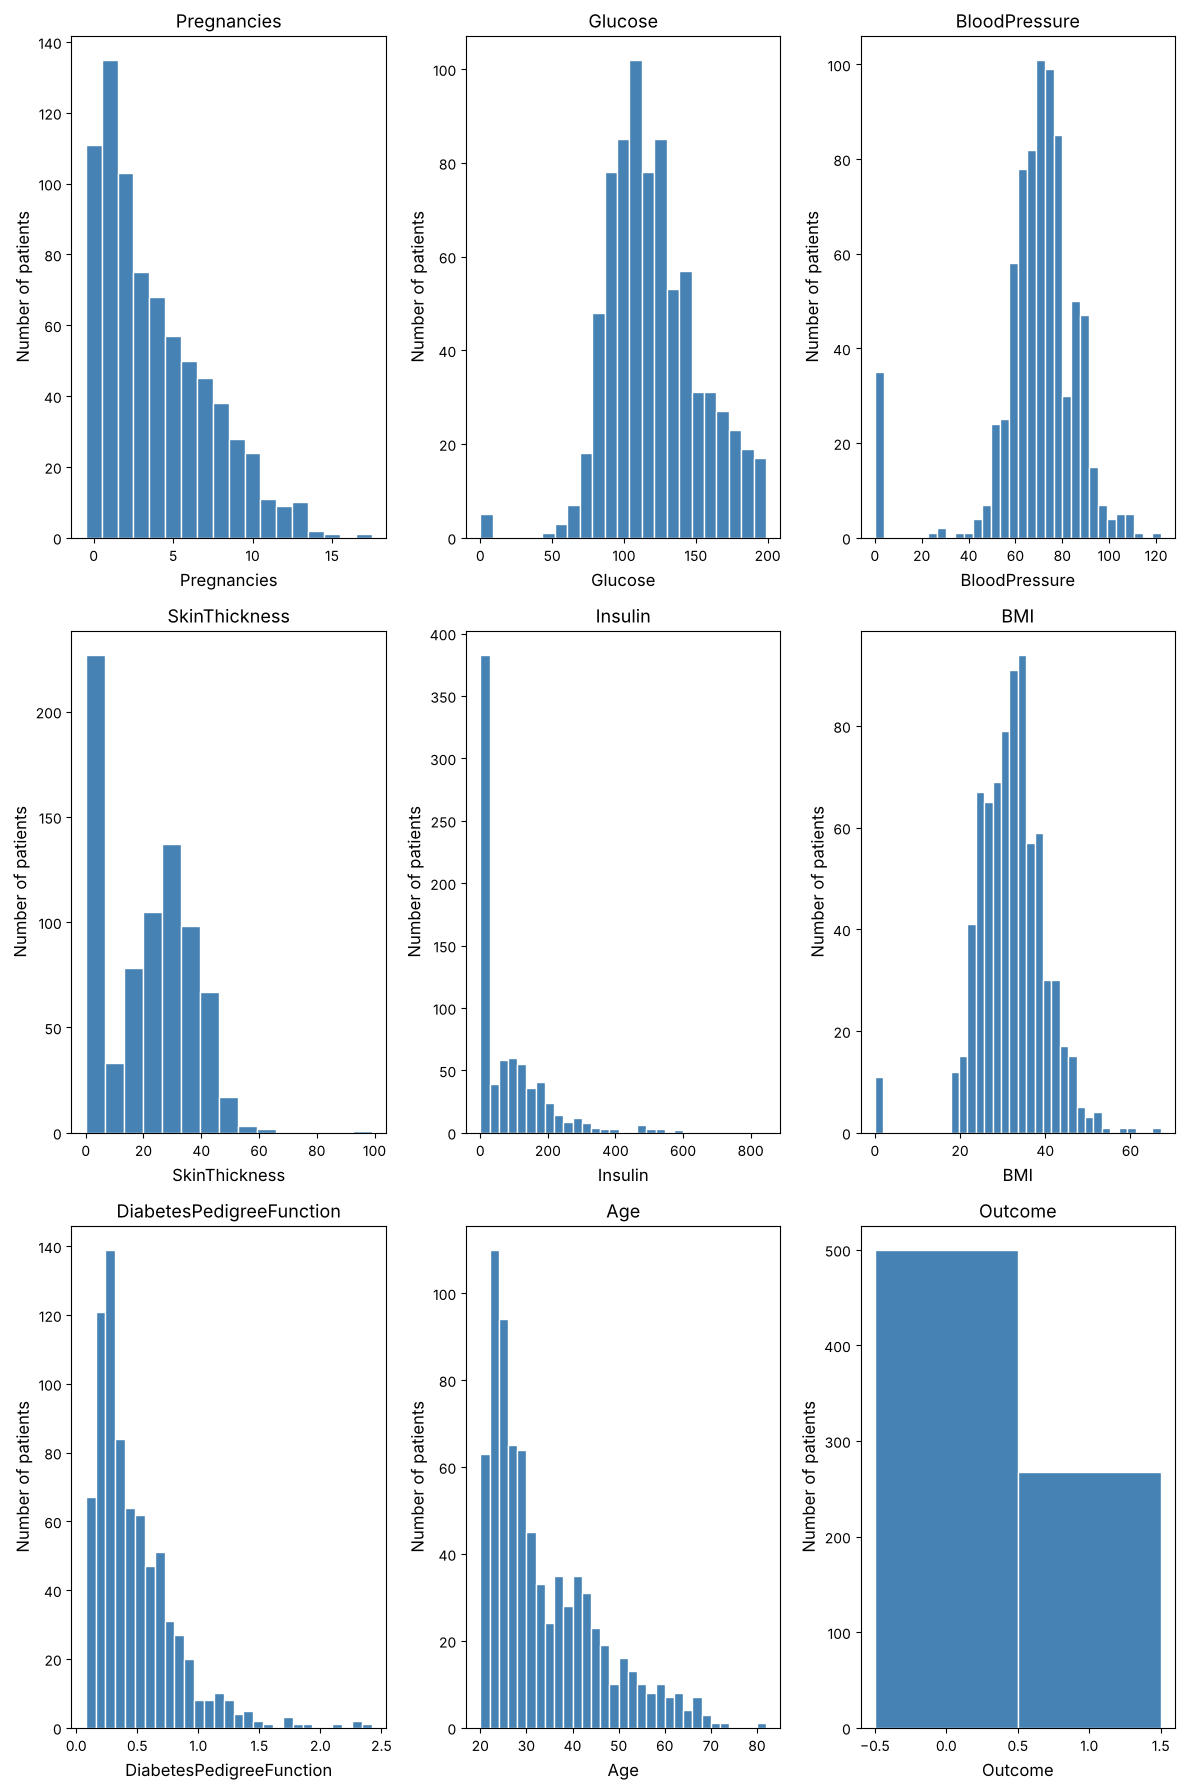

In [19]:
# Plot a histogram for each feature. Define the size of the figure (12,18); change the number of bins as well and the xlabel and ylabel sizes
fig, axes = plt.subplots(3, 3, figsize=(12, 18))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(data[col], bins=bins[col], color='steelblue', edgecolor='white')
    ax.set_title(col, fontsize=13)
    ax.set_xlabel(col, fontsize=12)
    ax.set_ylabel('Number of patients', fontsize=12)
plt.tight_layout()
plt.show()

**Comments on the histograms.**
* **Glucose, BloodPressure and BMI** look roughly bell-shaped (approximately normal), except for an isolated bar at **0**.
* **SkinThickness** and especially **Insulin** have a huge bar at 0 (227 and 374 patients): these are not real measurements but missing values coded as 0 (Section 6).
* **Insulin, DiabetesPedigreeFunction, Age and Pregnancies** are **right-skewed**: most values are small and there is a long tail of large values.
* **Outcome** shows the class imbalance (500 vs 268).

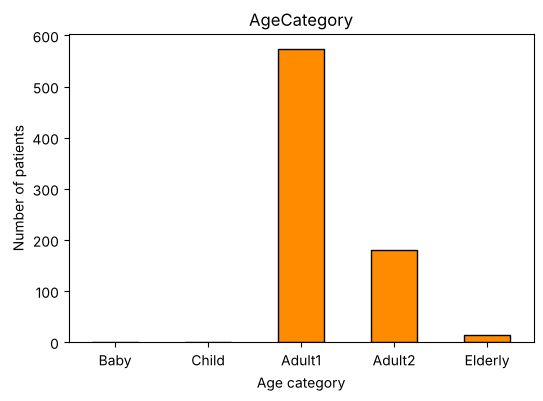

In [20]:
# Plot the categories of the "age category" feature using bars
ax = data['AgeCategory'].value_counts(sort=False).plot(kind='bar', color='darkorange', edgecolor='black', figsize=(6, 4))
ax.set_xlabel('Age category'); ax.set_ylabel('Number of patients'); ax.set_title('AgeCategory')
plt.xticks(rotation=0); plt.show()

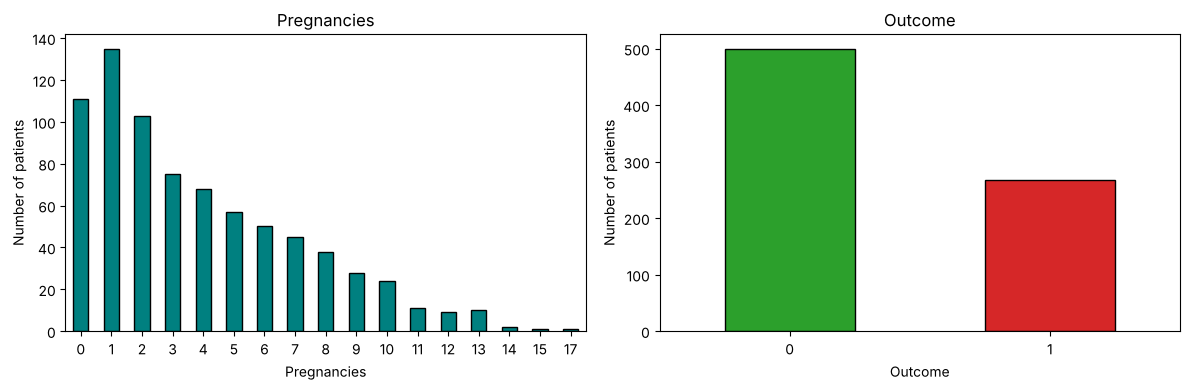

Most frequent value of Pregnancies: 1 ( 135 patients )


In [21]:
# Do the same for the features "Pregnancies" and "Outcome". Which is the most frequent value for the feature "Pregnancies"?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data['Pregnancies'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_xlabel('Pregnancies'); axes[0].set_ylabel('Number of patients'); axes[0].set_title('Pregnancies')
data['Outcome'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['tab:green', 'tab:red'], edgecolor='black')
axes[1].set_xlabel('Outcome'); axes[1].set_ylabel('Number of patients'); axes[1].set_title('Outcome')
for ax in axes: ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print("Most frequent value of Pregnancies:", data['Pregnancies'].mode()[0],
      "(", data['Pregnancies'].value_counts().max(), "patients )")

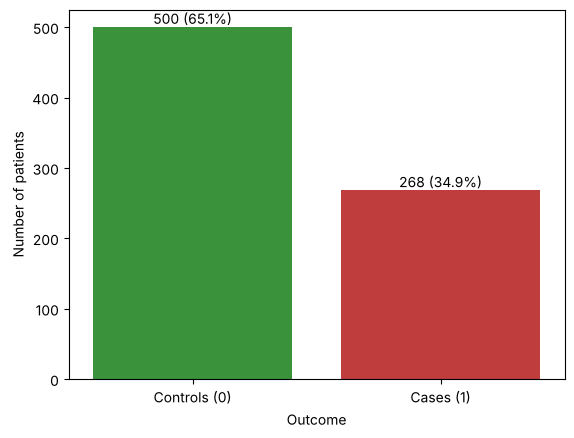

In [22]:
# Plot the number of cases and controls. Can you see visually if the classes are balanced?
ax = sns.countplot(x='Outcome', data=data, hue='Outcome', palette=['tab:green', 'tab:red'], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Controls (0)', 'Cases (1)'])
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{int(p.get_height())} ({p.get_height() / len(data):.1%})",
                    (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
ax.set_ylabel('Number of patients'); plt.show()

**Answer.** The most frequent value of Pregnancies is **1** (135 patients). In the cases/controls plot the bar of controls is almost twice as high as the bar of cases, so we can see at a glance that the **classes are not balanced** (65 % / 35 %).

#### b) Plot boxplots

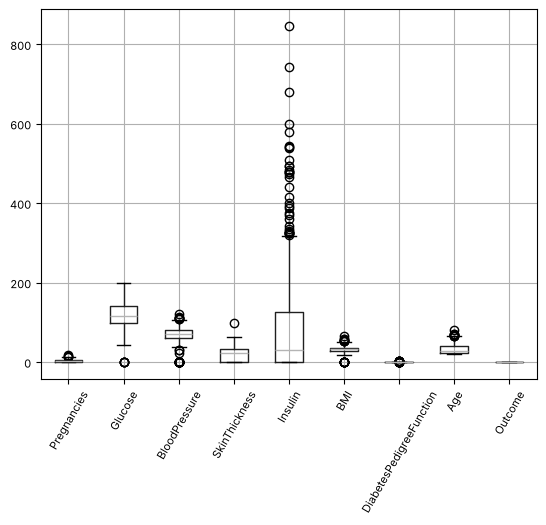

In [23]:
# Check the following plot, do you think this is a good one? How you can improve this figure?
boxplot = data.boxplot(grid=True, rot=60, fontsize=8)

**Answer.** It is **not a good figure**. All variables share the same y axis, but their scales are completely different (Insulin reaches 846 while DiabetesPedigreeFunction is below 2.5 and Outcome is 0/1). As a result the boxes of most variables are squashed into a flat line and we cannot read their median, quartiles or outliers. Also `Outcome` is categorical, so a boxplot of it makes no sense.

**Improvements:** (1) one subplot per variable, each with its own y axis (done below); or (2) standardise the variables first so they share a common scale; and add axis labels/titles and a larger figure.

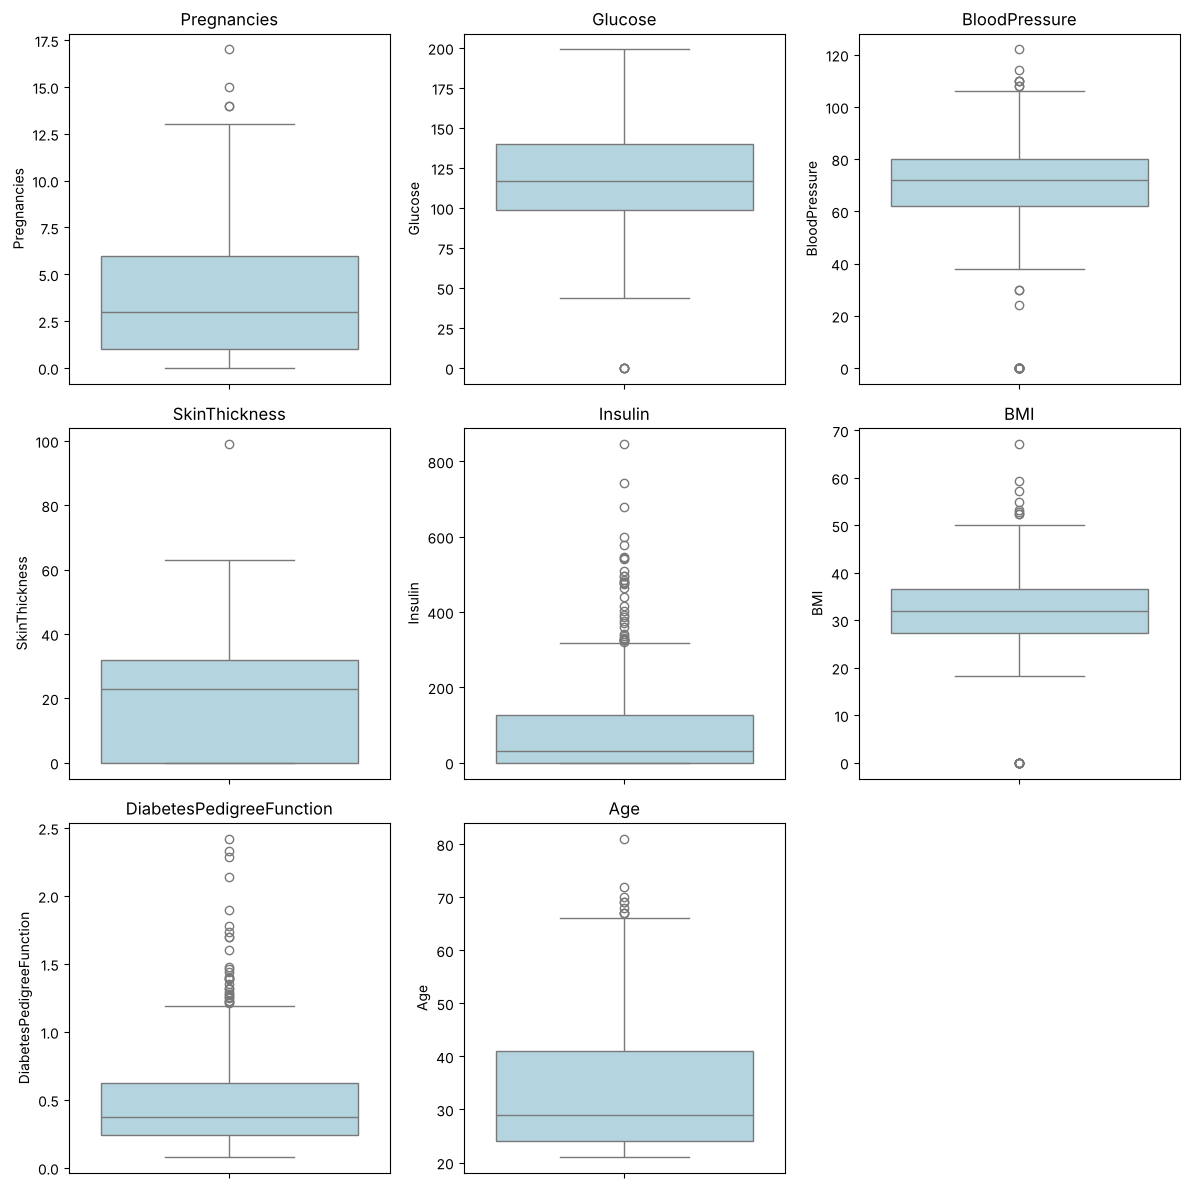

In [24]:
# Plot in different figures the boxplots related to each feature
features = [c for c in numeric_cols if c != 'Outcome']
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=data[col], ax=ax, color='lightblue')
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

Now each feature can be read: points beyond the whiskers (1.5·IQR) are potential outliers. Insulin and DiabetesPedigreeFunction have many high outliers, and Glucose, BloodPressure, SkinThickness and BMI have low "outliers" at 0, which are really missing values.

#### c) Plot scatter plots

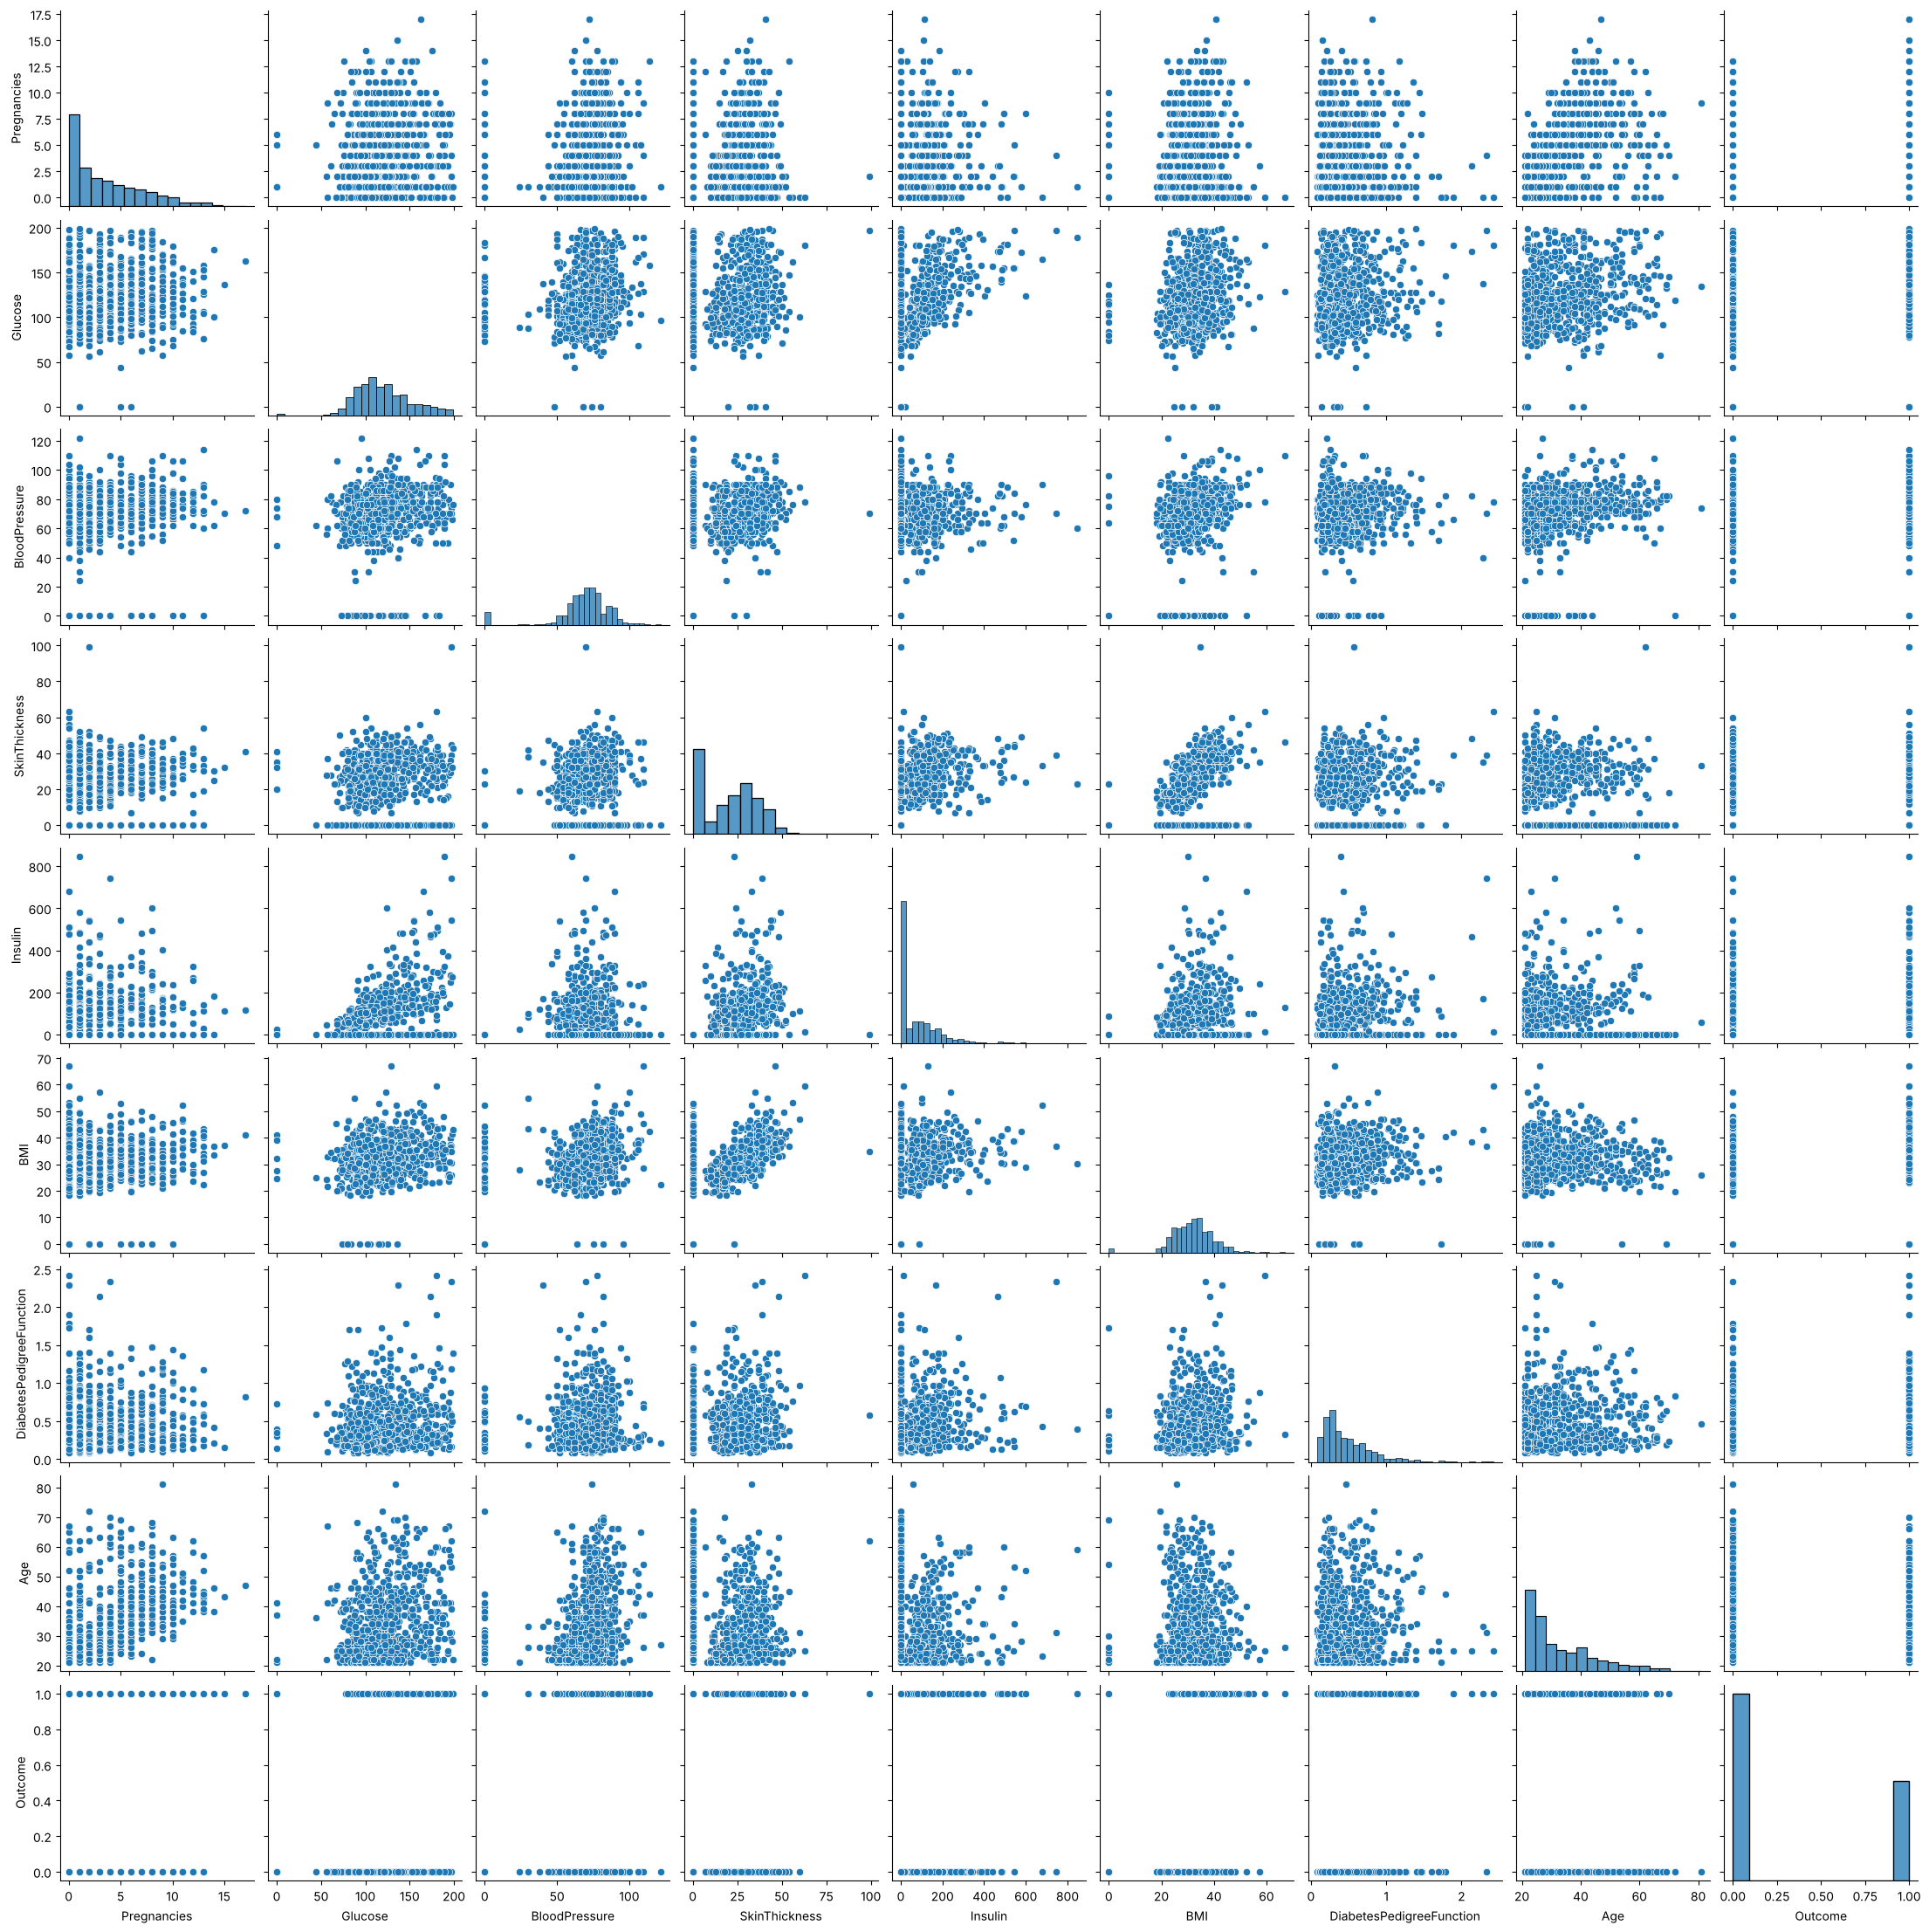

In [25]:
# Scatter plots. What are we showing in the following plot?
sns.pairplot(data)
plt.show()

**Answer.** `pairplot` draws a **scatter-plot matrix**: every off-diagonal cell is a scatter plot of one numerical variable against another (each point is a patient), and the diagonal shows the histogram of each variable. It lets us look for relationships between pairs of variables (e.g. Age vs Pregnancies or SkinThickness vs BMI show positive trends). `AgeCategory` is not drawn because it is not numerical. Rows/columns of `Outcome` are not very informative because it only takes the values 0 and 1. The vertical/horizontal lines of points at 0 are, again, the missing values.

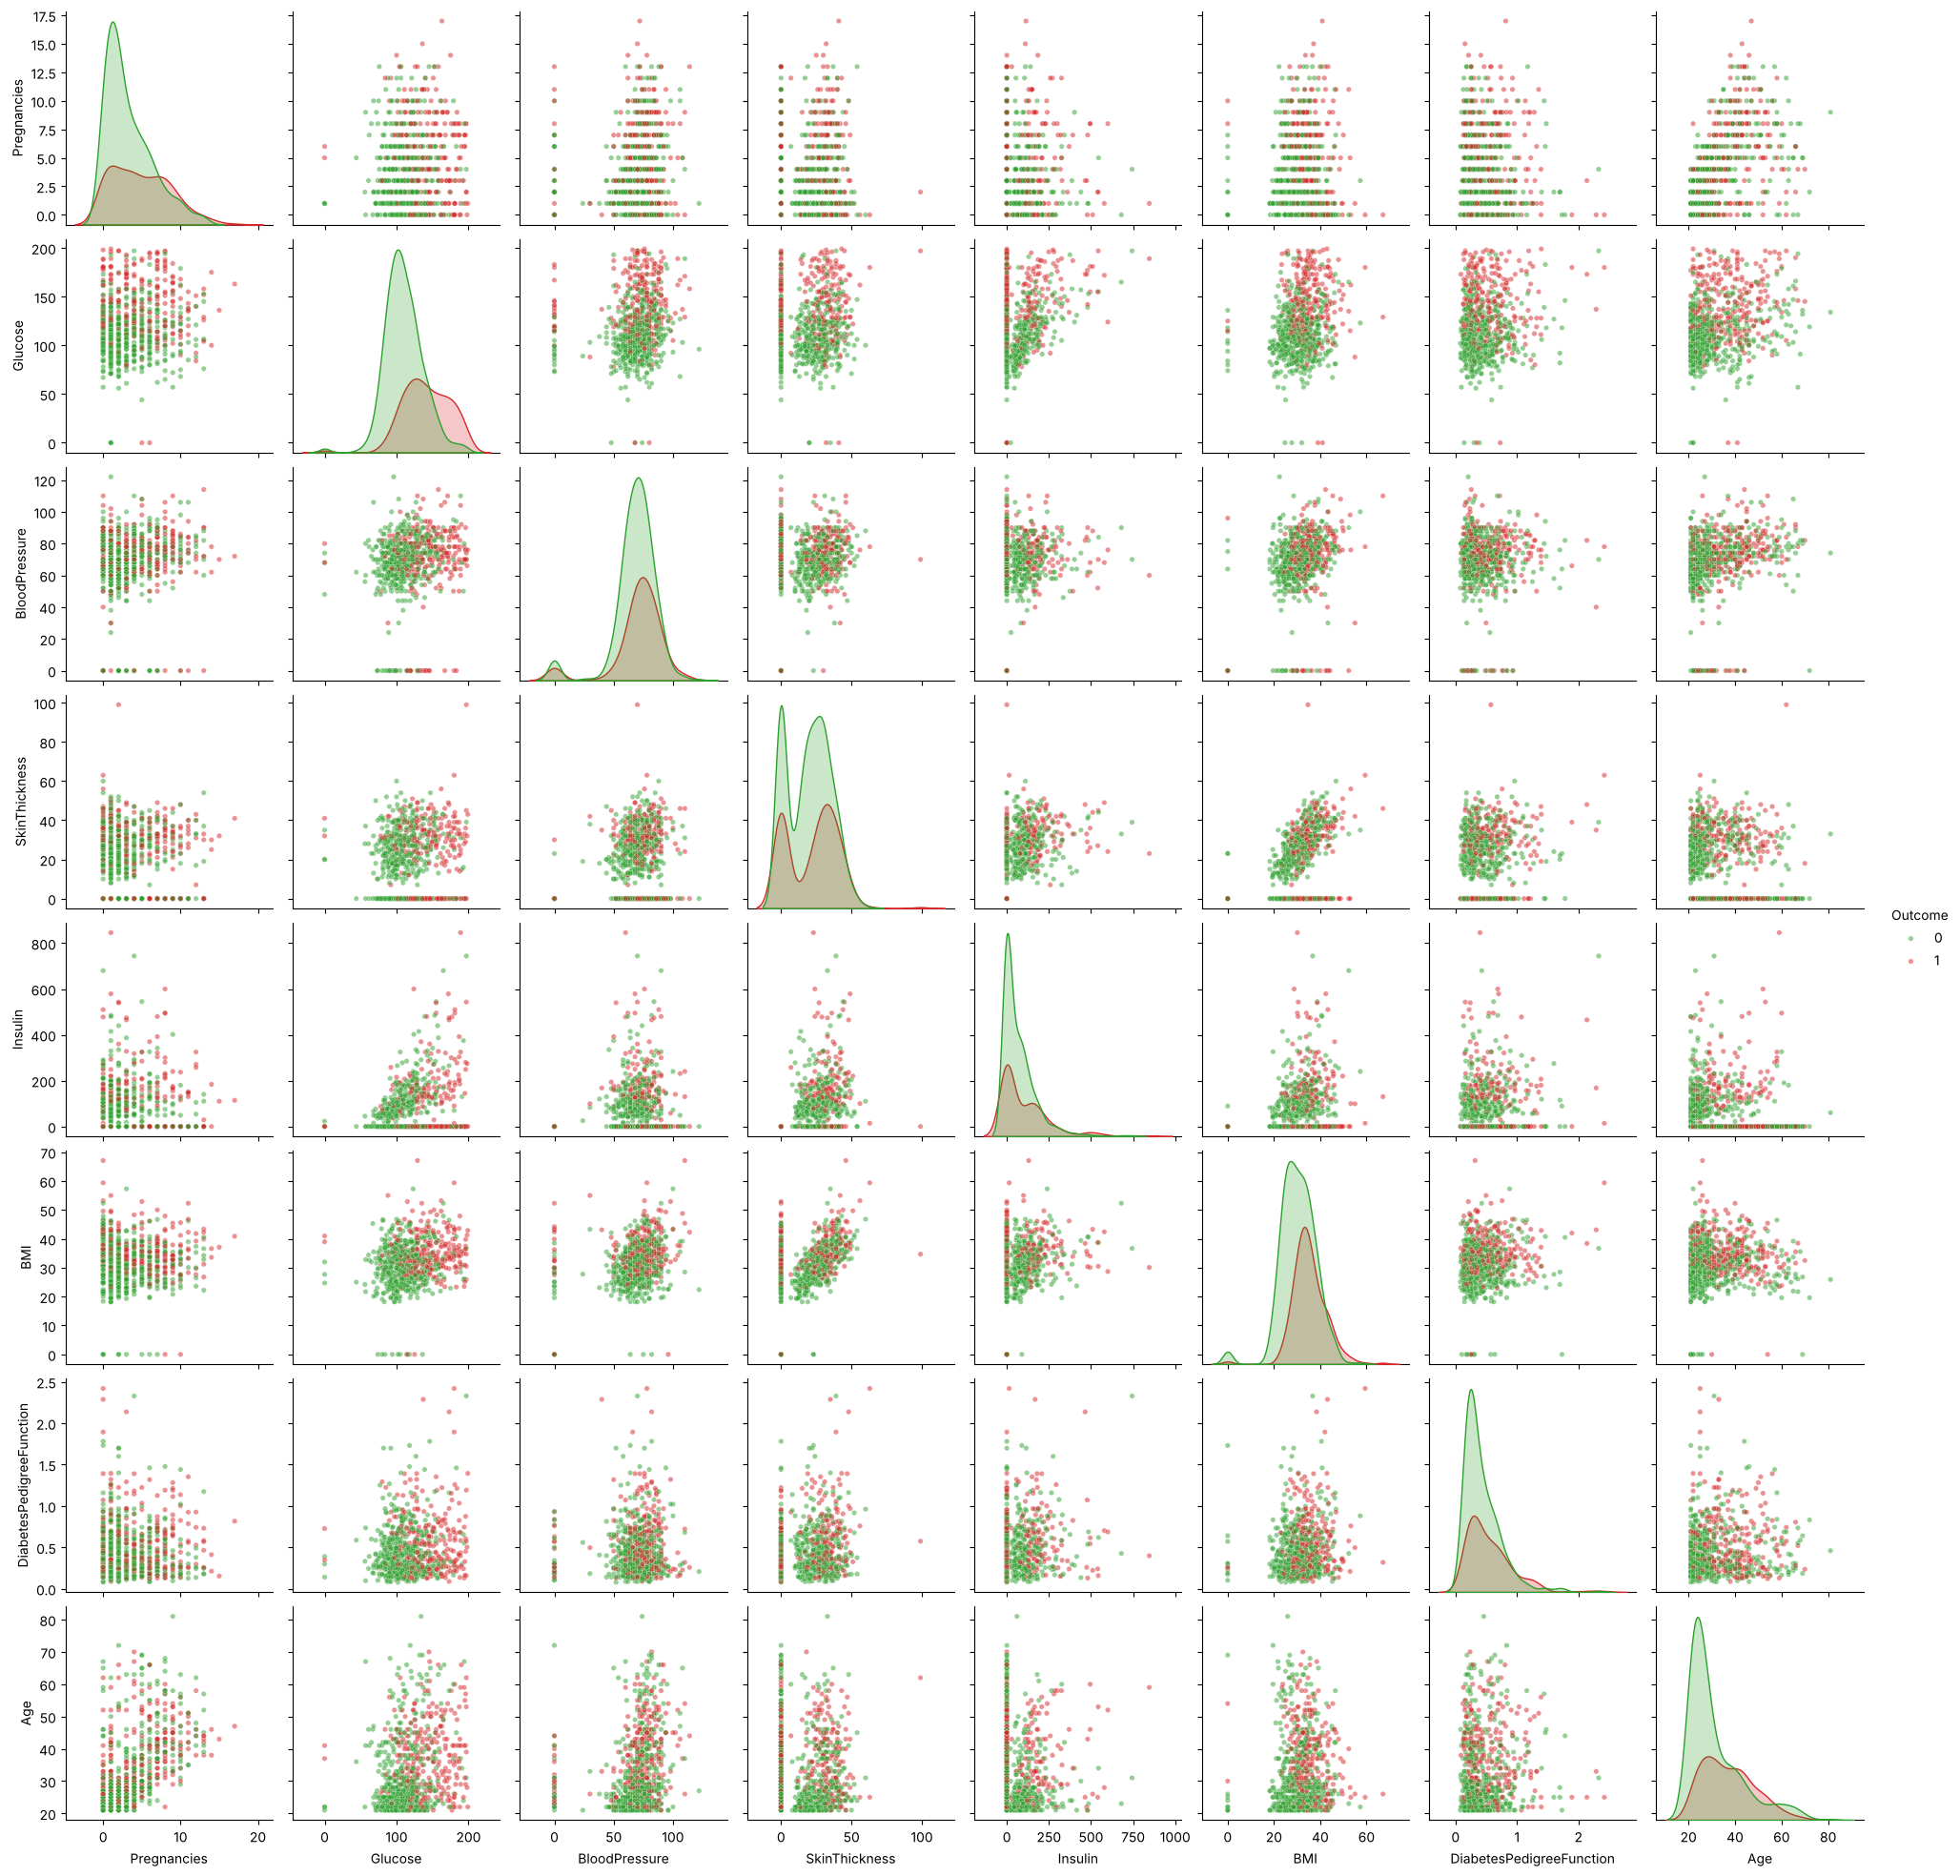

In [26]:
# Include the information of the outcome as the hue
sns.pairplot(data, vars=features, hue='Outcome', palette={0: 'tab:green', 1: 'tab:red'},
             plot_kws={'alpha': 0.5, 's': 15})
plt.show()

With `hue='Outcome'` each point is coloured by its class, and the diagonal shows one density per class. **Glucose** is the variable that separates the classes best (the red density is clearly shifted to higher values); **BMI** and **Age** also show some shift, while for BloodPressure or SkinThickness the two classes overlap almost completely. No single pair of variables separates the classes perfectly.

Useful link: https://seaborn.pydata.org/tutorial/categorical.html

## 5.- Basics of Grouping

In [27]:
# Can you extract some insights from the following results?
# observed=True: show only the AgeCategory levels that actually appear (Baby/Child would be all NaN)
data.groupby(['Outcome', 'AgeCategory'], observed=True).mean()

Pregnancies     Glucose  BloodPressure  SkinThickness  \
Outcome AgeCategory                                                          
0       Adult1          2.607843  108.401961      66.745098      20.703431   
        Adult2          6.457831  115.891566      75.180723      16.289157   
        Elderly         5.444444  127.000000      68.888889       3.666667   
1       Adult1          3.620482  139.716867      66.512048      23.295181   
        Adult2          7.010204  143.112245      77.530612      20.969388   
        Elderly         4.000000  159.750000      85.500000       4.500000   

                        Insulin        BMI  DiabetesPedigreeFunction  \
Outcome AgeCategory                                                    
0       Adult1        75.428922  30.093627                  0.426645   
        Adult2        42.903614  32.093976                  0.436795   
        Elderly        6.666667  23.344444                  0.504667   
1       Adult1        98.939759  35.821084                  0.581711   
        Adult2       106.795918  34.018367                  0.501347   
        Elderly        0.000000  34.525000                  0.459500   

                           Age  
Outcome AgeCategory             
0       Adult1       26.504902  
        Adult2       50.072289  
        Elderly      69.444444  
1       Adult1       29.891566  
        Adult2       47.989796  
        Elderly      67.250000

In [28]:
data.groupby('Outcome').mean(numeric_only=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


**Insights.** `groupby(['Outcome','AgeCategory']).mean()` computes the mean of every variable for each combination of class and age group.
* In every age group, **diabetic women have clearly higher Glucose** (e.g. ≈140 vs ≈108 mg/dl in Adult1). This is consistent with the diagnosis of diabetes being based on glucose.
* Overall (second table), diabetic women also have **higher BMI** (35.1 vs 30.3), **more pregnancies** (4.9 vs 3.3), a **higher DiabetesPedigreeFunction** (more family history) and are older (37 vs 31 years).
* Within each class, `Adult2` women have more pregnancies and higher blood pressure than `Adult1` women: part of the differences are an age effect, not only a disease effect. That is why it is useful to group by age as well.
* `Elderly` contains only 13 women, so its means are unreliable.
* Means of SkinThickness and Insulin are biased downwards by the zeros (missing values) — another reason to clean the data first.

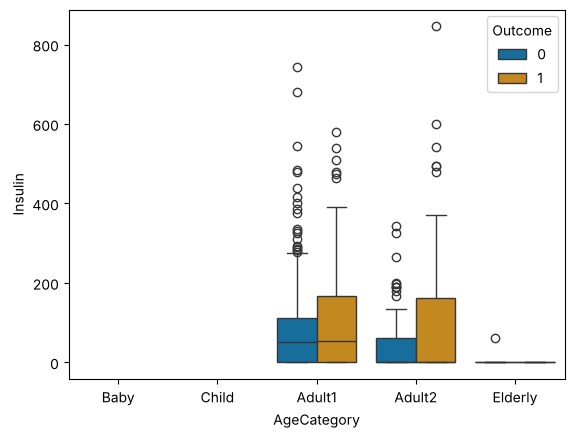

In [29]:
# Explain the code and the plot obtained
sns.boxplot(y='Insulin', x='AgeCategory',
            data=data,
            palette="colorblind",
            hue='Outcome')
plt.show()

**Answer.** This code draws, for each age category (x axis), two boxplots of `Insulin` (y axis): one for non-diabetic (`Outcome`=0) and one for diabetic (`Outcome`=1) women (`hue`); `palette="colorblind"` uses colours that are distinguishable by colour-blind people. `Baby` and `Child` are empty because there are no such patients. In `Adult1` the medians of both classes are similar (≈50 µU/ml) but diabetic patients have a higher upper quartile and more extreme values. In `Adult2` and `Elderly` more than half of the patients have Insulin = 0, so the median line sits at 0 and the boxes are squashed. This plot is dominated by the false zeros (missing values), so the comparison between classes is not reliable until they are treated.

## 6.- Dealing with Missing Values

#### a) Indicate which variables present null values and justify how you have identified them.

In [30]:
# Missing values
data.isnull().values.any()

np.False_

In [31]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
AgeCategory                 0
Outcome                     0
dtype: int64

In [32]:
# Identify the number of '0' values per feature
(data[numeric_cols] == 0).sum(axis=0)

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [33]:
# Identify the number of '0' values per observation
(data[numeric_cols] == 0).sum(axis=1)

0      1
1      2
2      2
3      1
4      1
      ..
763    1
764    2
765    1
766    2
767    2
Length: 768, dtype: int64

**Answer.** Formally there are **no null (NaN) values**: `isnull()` is False everywhere. However, the zeros reveal **hidden missing values**: with clinical knowledge we know that a living person cannot have 0 values of:

| Variable | Zeros | Meaning |
|---|---|---|
| Glucose | 5 | impossible → missing |
| BloodPressure | 35 | impossible (diastolic pressure 0) → missing |
| SkinThickness | 227 | impossible → missing |
| Insulin | 374 | impossible → missing (almost 49 % of the patients!) |
| BMI | 11 | impossible → missing |

On the other hand, the zeros of **Pregnancies** (111, women who were never pregnant) and **Outcome** (500, non-diabetic class) are **valid values**, and DiabetesPedigreeFunction and Age have no zeros. So we identified missing values by combining `describe()` (min = 0), counting zeros per feature, and expert knowledge.

Are all of them missing values? we need clinical/expert knowledge, for example, BMI cannot be 0; Glucose cannot be zero

##### What can we do?

We can eliminate these observations or we can replace them with a constant or with a statistic. Deleting every patient with at least one missing value would remove **376 of the 768 patients (49 %)**, which is too much information lost for such a small dataset. That is why we will impute them.

#### b) Replace null with constant ('0')

In [34]:
# We don't have this situation in our dataset (there are no NaN, missing values are already coded as '0').
# If there were NaNs, this is how we would replace them with a constant:
data_constant = data.fillna(0)
print("NaN before:", data.isnull().sum().sum(), "| NaN after:", data_constant.isnull().sum().sum())

NaN before: 0 | NaN after: 0


Replacing missing values with a constant like 0 is a bad idea here: it introduces impossible values that distort the mean, the variance and the relationships between variables.

#### c) Replace zeros with mean value

In [35]:
# Variables where 0 means "missing"
cols_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

data_clean = data.copy()
# 1) Convert the impossible zeros into real missing values (NaN)
data_clean[cols_missing] = data_clean[cols_missing].replace(0, np.nan)
print("Missing values per variable:\n", data_clean[cols_missing].isnull().sum())

Missing values per variable:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [36]:
# 2) Replace each NaN with the mean of the *valid* (non-zero) values of that variable.
#    (If we computed the mean including the zeros, the mean itself would be biased downwards.)
means = data_clean[cols_missing].mean()
print("Means used for imputation:\n", means.round(2))
data_clean[cols_missing] = data_clean[cols_missing].fillna(means)

print("\nZeros left:\n", (data_clean[cols_missing] == 0).sum())
data_clean.describe()

Means used for imputation:
 Glucose          121.69
BloodPressure     72.41
SkinThickness     29.15
Insulin          155.55
BMI               32.46
dtype: float64

Zeros left:
 Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.790942,85.021108,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,155.548223,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,155.548223,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


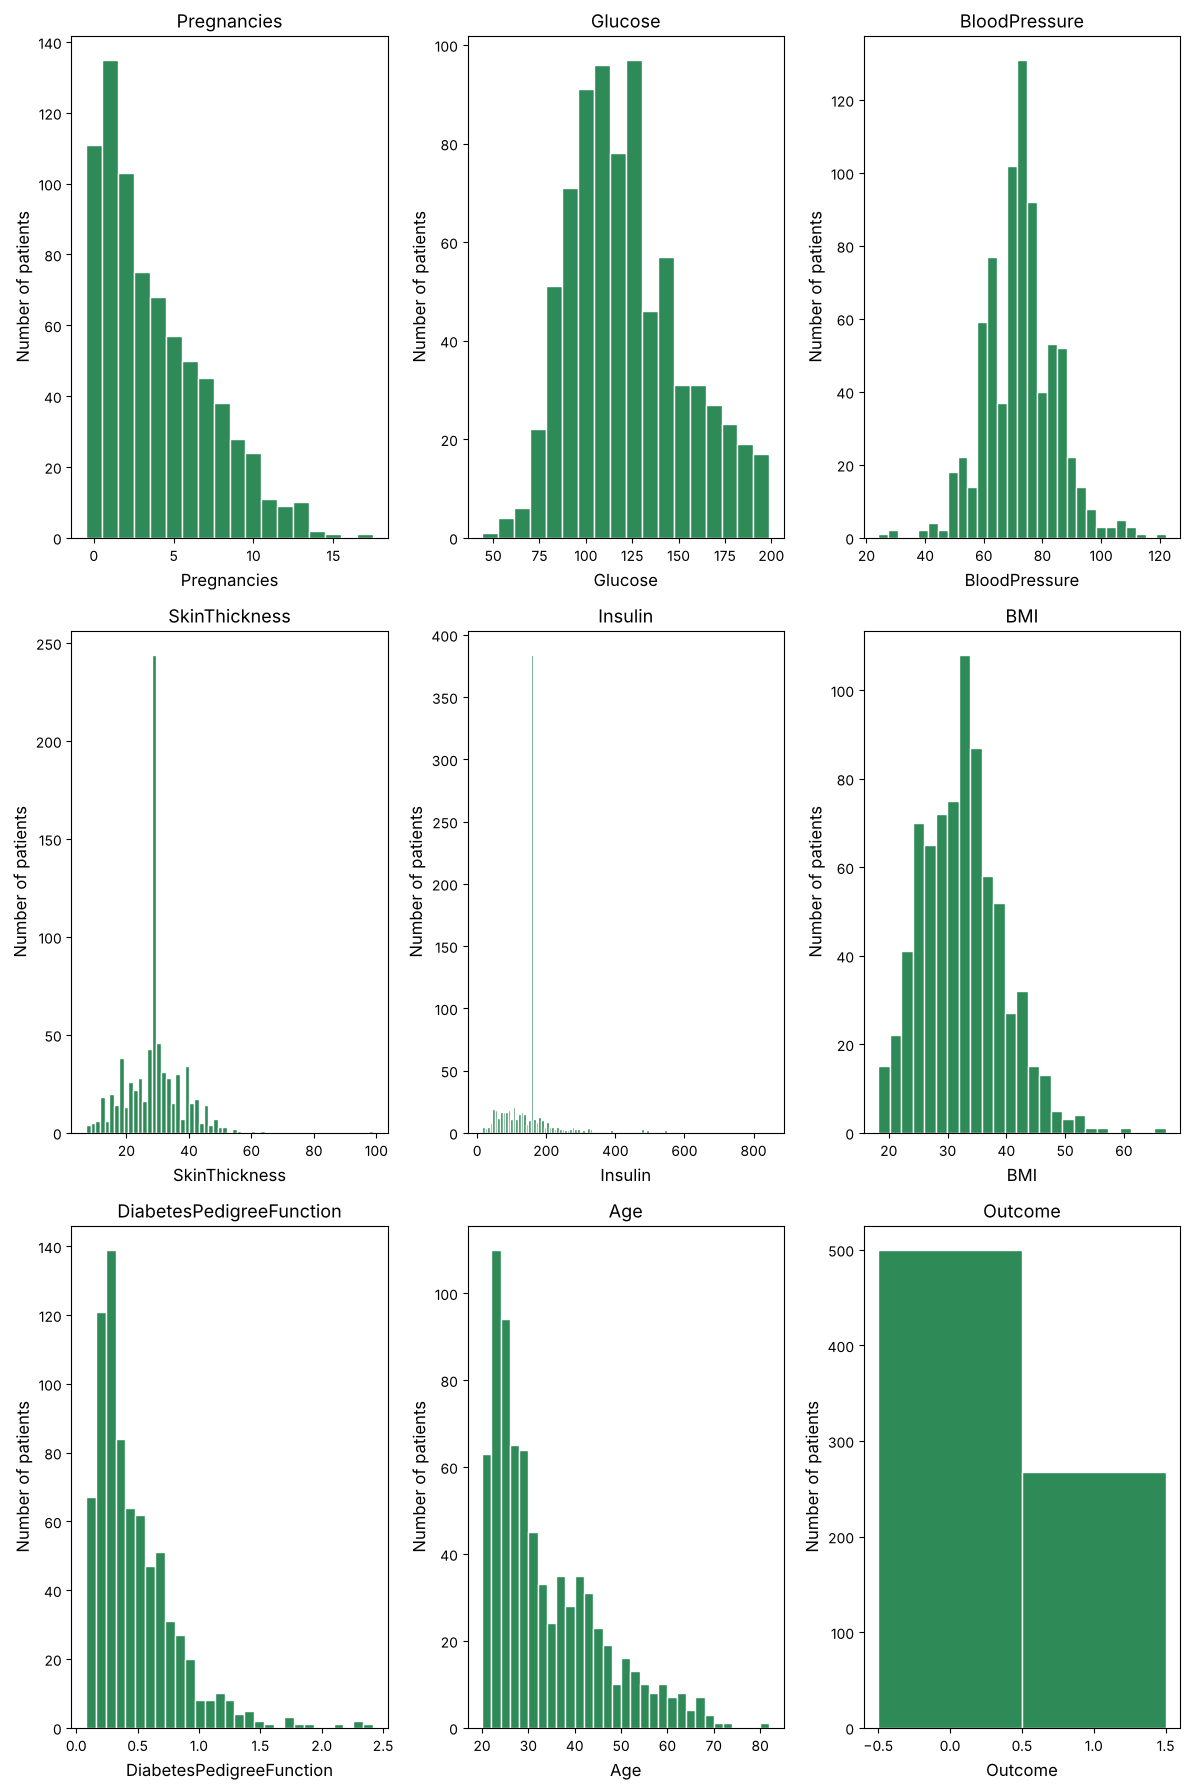

In [37]:
# Plot the histograms again, can you observe any differences? discuss them
fig, axes = plt.subplots(3, 3, figsize=(12, 18))
for ax, col in zip(axes.ravel(), numeric_cols):
    b = bins[col] if col in ['Pregnancies', 'Outcome', 'Age'] else np.histogram_bin_edges(data_clean[col], bins='fd')
    ax.hist(data_clean[col], bins=b, color='seagreen', edgecolor='white')
    ax.set_title(col, fontsize=13)
    ax.set_xlabel(col, fontsize=12); ax.set_ylabel('Number of patients', fontsize=12)
plt.tight_layout(); plt.show()

**Discussion.**
* The isolated bars at 0 in Glucose, BloodPressure and BMI have disappeared and these variables now look clearly bell-shaped; their minimums are now realistic (44 mg/dl, 24 mm Hg, 18.2).
* The mean of each variable increases (e.g. SkinThickness from 20.5 to 29.2 and Insulin from 79.8 to 155.5), because the false zeros were pulling it down.
* **Drawback:** in SkinThickness (30 % imputed) and Insulin (49 % imputed) a very tall artificial peak appears exactly at the mean. Mean imputation **reduces the variance** and weakens correlations of these variables, because many patients now share the same invented value. In Insulin the median and the 3rd quartile are now equal to the imputed mean. Better alternatives would be the median (more robust for skewed Insulin), imputation by class/group, or model-based imputation (KNN, regression).
* Strictly speaking, to avoid information leakage the imputation statistics should be computed on the training set only. Since here the statistics are simple means over 768 patients the effect is negligible, but in a real pipeline we would put the imputer inside the training process.

## 7.- Dealing with outliers

a) Indicate which variables present anomalous values that could be eliminated and justify how you have identified them. You can rely on other visualization tools not seen in theory, such as the box plots.

#### a) Identifying outliers with zscore
Use z-score for each sample on the data set and specify a threshold (for example 2.5, 3, 3.5 or more standard deviations).

In [38]:
# calculate z-scores with stats: z = (x - mean) / std
z_scores = stats.zscore(data['BMI'])

# Here, we are considering 3 times the standard deviation.
abs_z_scores = np.abs(z_scores)
no_outliers = (abs_z_scores < 3)
new_data = data[no_outliers]
print("Patients removed (BMI, raw data):", (~no_outliers).sum())
print("Their BMI values:", sorted(data.loc[~no_outliers, 'BMI'].tolist()))

Patients removed (BMI, raw data): 14
Their BMI values: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 57.3, 59.4, 67.1]


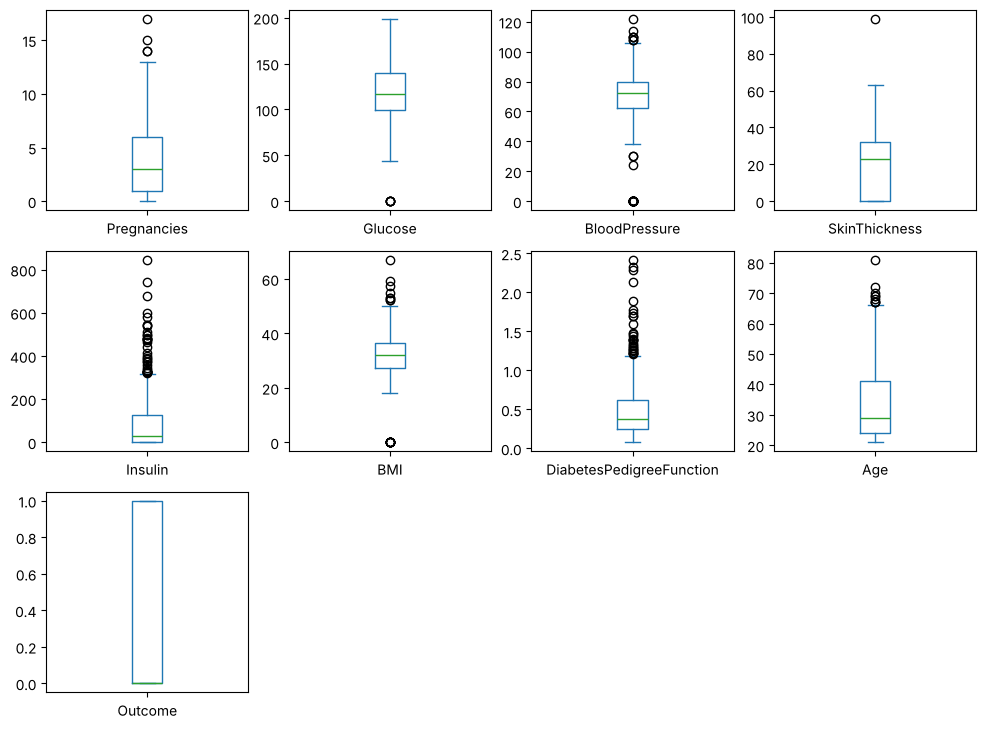

In [39]:
data.plot(kind='box', subplots=True, layout=(4, 4), sharex=False, sharey=False, figsize=(12, 12))
plt.show()

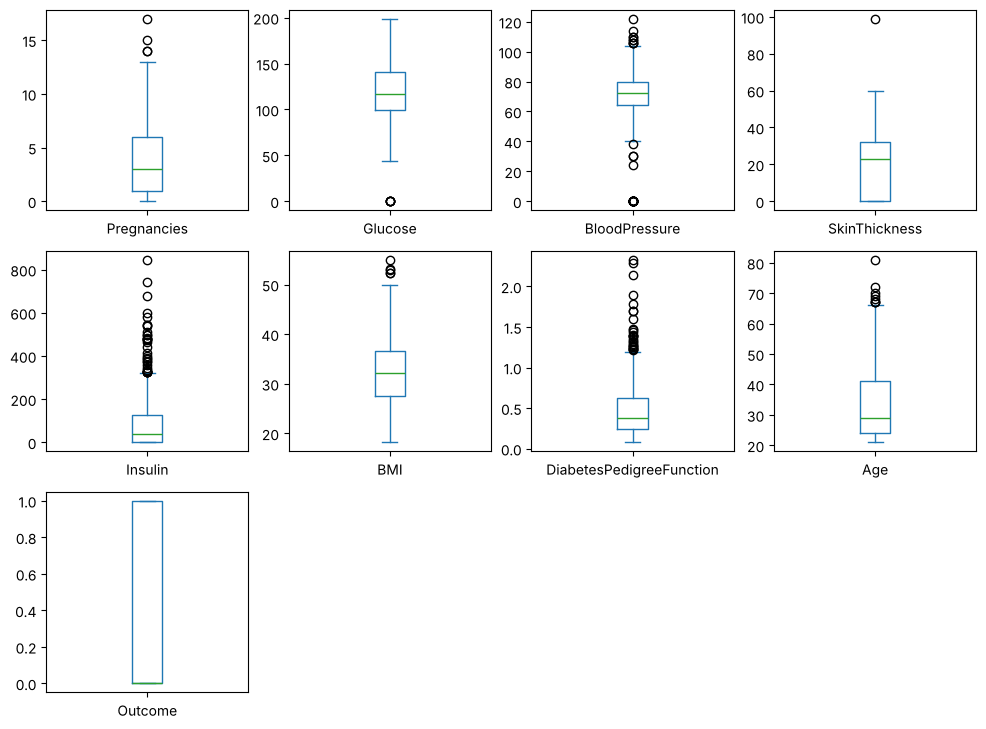

In [40]:
new_data.plot(kind='box', subplots=True, layout=(4, 4), sharex=False, sharey=False, figsize=(12, 12))
plt.show()

On the raw data the |z| > 3 rule on BMI removes 14 patients: 11 of them have BMI = 0 (the missing values!) and 3 have very high BMI (> 57). This shows that outlier detection should be done **after** fixing the missing values, otherwise we confuse missing data with anomalies. From now on we work with `data_clean`.

In [41]:
# z-score analysis of every feature (on the cleaned data) for several thresholds
z = pd.DataFrame(np.abs(stats.zscore(data_clean[features])), columns=features, index=data_clean.index)
summary_z = pd.DataFrame({f'|z|>{t}': (z > t).sum() for t in [2.5, 3, 3.5]})
summary_z

,|z|>2.5,|z|>3,|z|>3.5
Pregnancies,14,4,1
Glucose,3,0,0
BloodPressure,17,8,4
SkinThickness,10,4,3
Insulin,24,19,17
BMI,10,5,3
DiabetesPedigreeFunction,20,11,9
Age,21,5,1


Pregnancies               :  4 outliers -> values [14, 14, 15, 17]
Glucose                   :  0 outliers -> values []
BloodPressure             :  8 outliers -> values [24.0, 30.0, 30.0, 110.0, 110.0, 110.0, 114.0, 122.0]
SkinThickness             :  4 outliers -> values [56.0, 60.0, 63.0, 99.0]
Insulin                   : 19 outliers -> values [415.0, 440.0, 465.0, 474.0, 478.0, 480.0, 480.0, 485.0, 495.0, 495.0, 510.0, 540.0, 543.0, 545.0, 579.0, 600.0, 680.0, 744.0, 846.0]
BMI                       :  5 outliers -> values [53.2, 55.0, 57.3, 59.4, 67.1]
DiabetesPedigreeFunction  : 11 outliers -> values [1.48, 1.6, 1.7, 1.7, 1.73, 1.78, 1.89, 2.14, 2.29, 2.33, 2.42]
Age                       :  5 outliers -> values [69, 69, 70, 72, 81]

Rows kept if we remove |z|>3 in ANY feature: 719 of 768


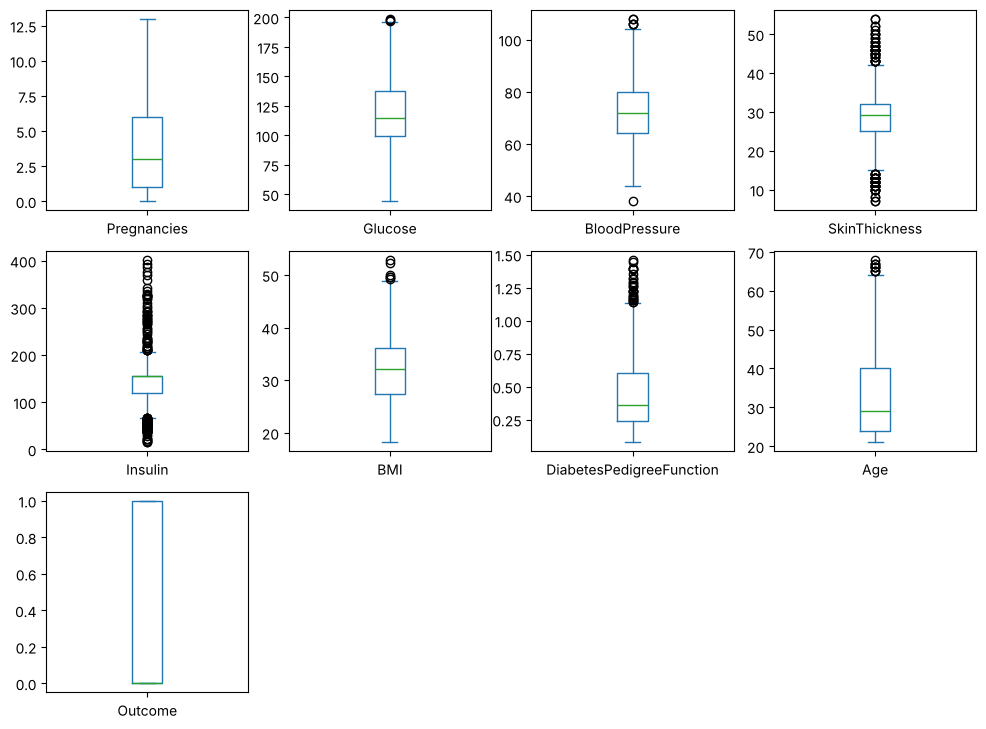

In [42]:
# Which patients are outliers in each variable with threshold 3, and how do the boxplots change if we remove them?
for col in features:
    idx = np.where(z[col] > 3)[0]
    print(f"{col:26s}: {len(idx):2d} outliers -> values {sorted(data_clean[col].iloc[idx].round(2).tolist())}")
mask_z = (z < 3).all(axis=1)
data_no_out_z = data_clean[mask_z]
print("\nRows kept if we remove |z|>3 in ANY feature:", mask_z.sum(), "of", len(data_clean))
data_no_out_z.plot(kind='box', subplots=True, layout=(4, 4), sharex=False, sharey=False, figsize=(12, 12))
plt.show()

#### b) Identifying Outliers with Interquartile Range

In [43]:
Q1 = data_clean[features].quantile(0.25)
Q3 = data_clean[features].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

Pregnancies                  5.000000
Glucose                     40.500000
BloodPressure               16.000000
SkinThickness                7.000000
Insulin                     34.048223
BMI                          9.100000
DiabetesPedigreeFunction     0.382500
Age                         17.000000
dtype: float64


In [44]:
# A value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR (the boxplot whiskers)
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
out_iqr = (data_clean[features] < lower) | (data_clean[features] > upper)
pd.DataFrame({'lower limit': lower, 'upper limit': upper, 'n outliers (IQR)': out_iqr.sum(),
              'n outliers (|z|>3)': (z > 3).sum()})

,lower limit,upper limit,n outliers (IQR),n outliers (|z|>3)
Pregnancies,-6.500000,13.500000,4,4
Glucose,39.000000,201.000000,0,0
BloodPressure,40.000000,104.000000,14,8
SkinThickness,14.500000,42.500000,87,4
Insulin,70.427665,206.620558,164,19
BMI,13.850000,50.250000,8,5
DiabetesPedigreeFunction,-0.330000,1.200000,29,11
Age,-1.500000,66.500000,9,5


In [45]:
print("Rows kept if we remove IQR outliers in ANY feature:", (~out_iqr.any(axis=1)).sum(), "of", len(data_clean))

Rows kept if we remove IQR outliers in ANY feature: 515 of 768


**Answer.**
* The **z-score** method (|z| > 3) flags few values: mainly very high **Insulin** (19, values > 410 µU/ml), **DiabetesPedigreeFunction** (11), **BloodPressure** (8, very low or very high), BMI (5, ≥ 53), Age (5, > 68), Pregnancies (4, ≥ 14) and SkinThickness (4, including an implausible 99 mm).
* The **IQR** method flags many more (e.g. 164 in Insulin, 87 in SkinThickness). This is an artefact of the mean imputation: so many patients share the imputed value that the IQR becomes tiny and every real measurement looks "anomalous". With skewed or imputed variables the IQR rule is too aggressive; the z-score also assumes approximate normality, so both must be interpreted with care.
* **Decision:** most of these values are **clinically plausible** (a woman can have 14 pregnancies, an insulin of 600 µU/ml or a BMI of 60, especially in a diabetic population) and they are frequently diabetic patients, i.e. they carry information about the minority class. With only 768 patients, removing them would lose information. Only clearly impossible values (such as the zeros, already treated) should be removed/corrected. Therefore **we keep all 768 patients** in the preprocessed dataset; outlier removal remains an option to evaluate later with the models (e.g. SkinThickness = 99 mm is a strong candidate for a data-entry error).

## 8.- Dealing with imbalance classes
This occurs when the number of samples in one class is much higher than the number of samples in the another class. Important to avoid bias

#### a) Undersampling
Remove randomly from the majority class, with or without replacement.

In [46]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

X_all = data_clean[features]
y_all = data_clean['Outcome']
print("Original:", Counter(y_all))

rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_all, y_all)
print("Undersampling:", Counter(y_under))

Original: Counter({0: 500, 1: 268})
Undersampling: Counter({0: 268, 1: 268})


The positive label considered as the minority class is 1


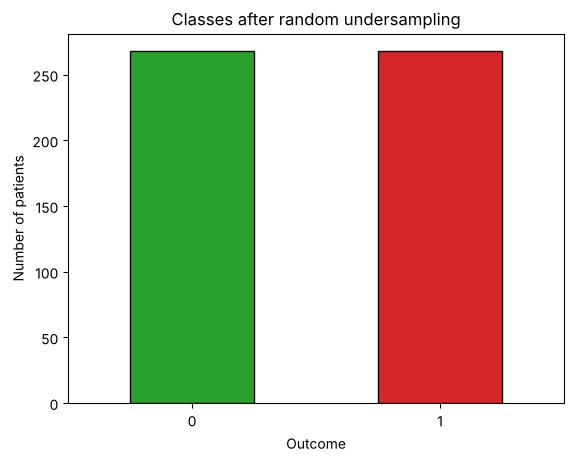

In [47]:
minority = y_all.value_counts().idxmin()
print(f"The positive label considered as the minority class is {minority}")
pd.Series(y_under).value_counts().sort_index().plot(kind='bar', color=['tab:green', 'tab:red'], edgecolor='black')
plt.title('Classes after random undersampling'); plt.xlabel('Outcome'); plt.ylabel('Number of patients')
plt.xticks(rotation=0); plt.show()

Undersampling removes 232 random controls, leaving 268 + 268 = 536 patients. The classes are balanced, but **we throw away 30 % of the data**, which is costly in a small dataset.

#### b) Random Oversampling
Randomly duplicate examples in the minority class.

In [48]:
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_all, y_all)
print(Counter(y_over))

Counter({1: 500, 0: 500})


Random oversampling duplicates 232 random diabetic patients (268 → 500). No information is lost, but exact copies can make the model **overfit** those repeated patients.

#### C) SMOTE

SMOTE is a method that over-samples the minority ('abnormal') class
https://arxiv.org/abs/1106.1813

https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html#imblearn.over_sampling.SMOTE

In [49]:
sm = SMOTE(random_state=42)
X_smote, y_smote = sm.fit_resample(X_all, y_all)
print("Samples", Counter(y_smote))

Samples Counter({1: 500, 0: 500})


SMOTE creates **synthetic** minority samples by interpolating between a minority patient and one of its k nearest minority neighbours (new = x + λ·(x_neighbour − x), λ∈[0,1]), so it does not just copy patients.

**Important:** resampling must be applied **only to the training set**, after the train/test split. If we resample before splitting, copies (or interpolations) of the same patient end up both in training and test and the test results become optimistic. The test set must keep the real class proportions. For this reason the resampled datasets are not saved as the preprocessed dataset.

## 9.- Feature transformation. One hot encoding

In [50]:
# Use one-hot-encoding for dealing with categorical data
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
onehot = ohe.fit_transform(data_clean[['AgeCategory']])
print("Categories found by OneHotEncoder:", ohe.categories_)
pd.DataFrame(onehot).describe()

Categories found by OneHotEncoder: [array(['Adult1', 'Adult2', 'Elderly'], dtype=object)]


,0,1,2
count,768.000000,768.000000,768.000000
mean,0.747396,0.235677,0.016927
std,0.434789,0.424698,0.129082
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000


In [51]:
# Benchmark the obtained results with the one you get when using get_dummies
dummies = pd.get_dummies(data_clean['AgeCategory'], prefix='Age', dtype=int)
dummies.head()

,Age_Baby,Age_Child,Age_Adult1,Age_Adult2,Age_Elderly
0,0,0,0,1,0
1,0,0,1,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,1,0,0


In [52]:
data_ohe = pd.concat([data_clean.drop(columns='AgeCategory'), dummies], axis=1)
data_ohe.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Age_Baby,Age_Child,Age_Adult1,Age_Adult2,Age_Elderly
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.0,768.0,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958,0.0,0.0,0.747396,0.235677,0.016927
std,3.369578,30.435949,12.096346,8.790942,85.021108,6.875151,0.331329,11.760232,0.476951,0.0,0.0,0.434789,0.424698,0.129082
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,155.548223,32.400000,0.372500,29.000000,0.000000,0.0,0.0,1.000000,0.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,155.548223,36.600000,0.626250,41.000000,1.000000,0.0,0.0,1.000000,0.000000,0.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,0.0,0.0,1.000000,1.000000,1.000000


**Answer.** One-hot encoding transforms a categorical variable with K levels into K binary (0/1) columns, one per level, so that the model does not assume a false numeric order/distance between labels. Each row has a single 1.
* `OneHotEncoder` (scikit-learn) learns the categories **from the data it sees** → only the 3 observed levels (Adult1, Adult2, Elderly), giving 3 columns. Their means are the proportions of each level (74.7 %, 23.6 %, 1.7 %). It is the preferred option in ML pipelines because it can be fitted on the training set and then applied consistently to the test set (`handle_unknown`).
* `pd.get_dummies` uses the **categories defined in the `category` dtype** → 5 columns, including `Age_Baby` and `Age_Child`, which are always 0 (useless constant columns that should be removed).
* With linear models, one column is often dropped (`drop='first'` / `drop_first=True`) to avoid perfect collinearity (the dummies always sum to 1).

## 10.- Normalization

Note! This is a general example. If you are dividing your data into training and test, check carefully Section 12

#### a) Using MinMaxScaler()

In [53]:
# Use min_max scaler to normalize the data. Show the results after normalizing
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scaler = MinMaxScaler()
data_minmax = pd.DataFrame(scaler.fit_transform(data_ohe), columns=data_ohe.columns)
data_minmax.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Age_Baby,Age_Child,Age_Adult1,Age_Adult2,Age_Elderly
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.0,768.0,768.000000,768.000000,768.000000
mean,0.226180,0.501205,0.493930,0.240798,0.170130,0.291564,0.168179,0.204015,0.348958,0.0,0.0,0.747396,0.235677,0.016927
std,0.198210,0.196361,0.123432,0.095554,0.102189,0.140596,0.141473,0.196004,0.476951,0.0,0.0,0.434789,0.424698,0.129082
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
25%,0.058824,0.359677,0.408163,0.195652,0.129207,0.190184,0.070773,0.050000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
50%,0.176471,0.470968,0.491863,0.240798,0.170130,0.290389,0.125747,0.133333,0.000000,0.0,0.0,1.000000,0.000000,0.000000
75%,0.352941,0.620968,0.571429,0.271739,0.170130,0.376278,0.234095,0.333333,1.000000,0.0,0.0,1.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,0.0,1.000000,1.000000,1.000000


In [54]:
# Using minmax scaler, but now the range is [0,2]. Can you write the equation to do it?
scaler02 = MinMaxScaler(feature_range=(0, 2))
data_minmax02 = pd.DataFrame(scaler02.fit_transform(data_ohe), columns=data_ohe.columns)

# Manual check of the equation
manual = (data_ohe - data_ohe.min()) / (data_ohe.max() - data_ohe.min()) * (2 - 0) + 0
manual = manual.fillna(0)   # constant columns (Age_Baby, Age_Child) give 0/0
print("Max difference sklearn vs. equation:", np.abs(manual.values - data_minmax02.values).max())
data_minmax02.describe()

Max difference sklearn vs. equation: 4.440892098500626e-16


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Age_Baby,Age_Child,Age_Adult1,Age_Adult2,Age_Elderly
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.0,768.0,768.000000,768.000000,768.000000
mean,0.452359,1.002410,0.987861,0.481596,0.340260,0.583127,0.336359,0.408030,0.697917,0.0,0.0,1.494792,0.471354,0.033854
std,0.396421,0.392722,0.246864,0.191107,0.204378,0.281192,0.282945,0.392008,0.953903,0.0,0.0,0.869578,0.849396,0.258165
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
25%,0.117647,0.719355,0.816327,0.391304,0.258413,0.380368,0.141546,0.100000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
50%,0.352941,0.941935,0.983726,0.481596,0.340260,0.580777,0.251494,0.266667,0.000000,0.0,0.0,2.000000,0.000000,0.000000
75%,0.705882,1.241935,1.142857,0.543478,0.340260,0.752556,0.468190,0.666667,2.000000,0.0,0.0,2.000000,0.000000,0.000000
max,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.0,0.0,2.000000,2.000000,2.000000


**Equation.** For a target range $[a, b]$:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}\,(b - a) + a \quad\Rightarrow\quad \text{for } [0,2]:\; x' = 2\,\frac{x - x_{min}}{x_{max} - x_{min}}$$

The check above shows that it gives exactly the same result as `MinMaxScaler(feature_range=(0,2))`. Min–max scaling is sensitive to outliers: one extreme value (e.g. Insulin = 846) compresses all the other values into a small part of the range.

#### b) Standardization
By applying standardization, each column will have mean 0 and the standard deviation 1

In [55]:
# Use StandardScaler to normalize data. Show the results after normalizing
std_scaler = StandardScaler()
data_std = pd.DataFrame(std_scaler.fit_transform(data_ohe), columns=data_ohe.columns)
data_std.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Age_Baby,Age_Child,Age_Adult1,Age_Adult2,Age_Elderly
count,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,768.0,768.0,7.680000e+02,7.680000e+02,7.680000e+02
mean,-6.476301e-17,-3.561966e-16,6.915764e-16,7.956598e-16,-3.330669e-16,3.515706e-16,2.451743e-16,1.931325e-16,7.401487e-17,0.0,0.0,-1.133353e-16,-7.170190e-17,-3.700743e-17
std,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,0.0,0.0,1.000652e+00,1.000652e+00,1.000652e+00
min,-1.141852e+00,-2.554131e+00,-4.004245e+00,-2.521670e+00,-1.665945e+00,-2.075119e+00,-1.189553e+00,-1.041549e+00,-7.321202e-01,0.0,0.0,-1.720105e+00,-5.552905e-01,-1.312194e-01
25%,-8.448851e-01,-7.212214e-01,-6.953060e-01,-4.727737e-01,-4.007289e-01,-7.215397e-01,-6.889685e-01,-7.862862e-01,-7.321202e-01,0.0,0.0,-1.720105e+00,-5.552905e-01,-1.312194e-01
50%,-2.509521e-01,-1.540881e-01,-1.675912e-02,8.087936e-16,-3.345079e-16,-8.363615e-03,-3.001282e-01,-3.608474e-01,-7.321202e-01,0.0,0.0,5.813597e-01,-5.552905e-01,-1.312194e-01
75%,6.399473e-01,6.103090e-01,6.282695e-01,3.240194e-01,-3.345079e-16,6.029301e-01,4.662269e-01,6.602056e-01,1.365896e+00,0.0,0.0,5.813597e-01,-5.552905e-01,-1.312194e-01
max,3.906578e+00,2.541850e+00,4.102655e+00,7.950467e+00,8.126238e+00,5.042087e+00,5.883565e+00,4.063716e+00,1.365896e+00,0.0,0.0,5.813597e-01,1.800859e+00,7.620822e+00


Standardization: $z = \frac{x-\mu}{\sigma}$. Every column now has mean ≈ 0 (values like 1e-17 are rounding errors). The std shown by `describe()` is 1.0007 and not exactly 1 because `describe()` uses the sample std (divides by n−1) while `StandardScaler` uses the population std (divides by n): $\sqrt{768/767}=1.00065$. Unlike min–max, the result is not bounded to a fixed interval. (Normalizing `Outcome` here is only to illustrate; the target and binary dummies would normally not be scaled.)

## 11.- Correlation

#### Plot the dispersion matrix

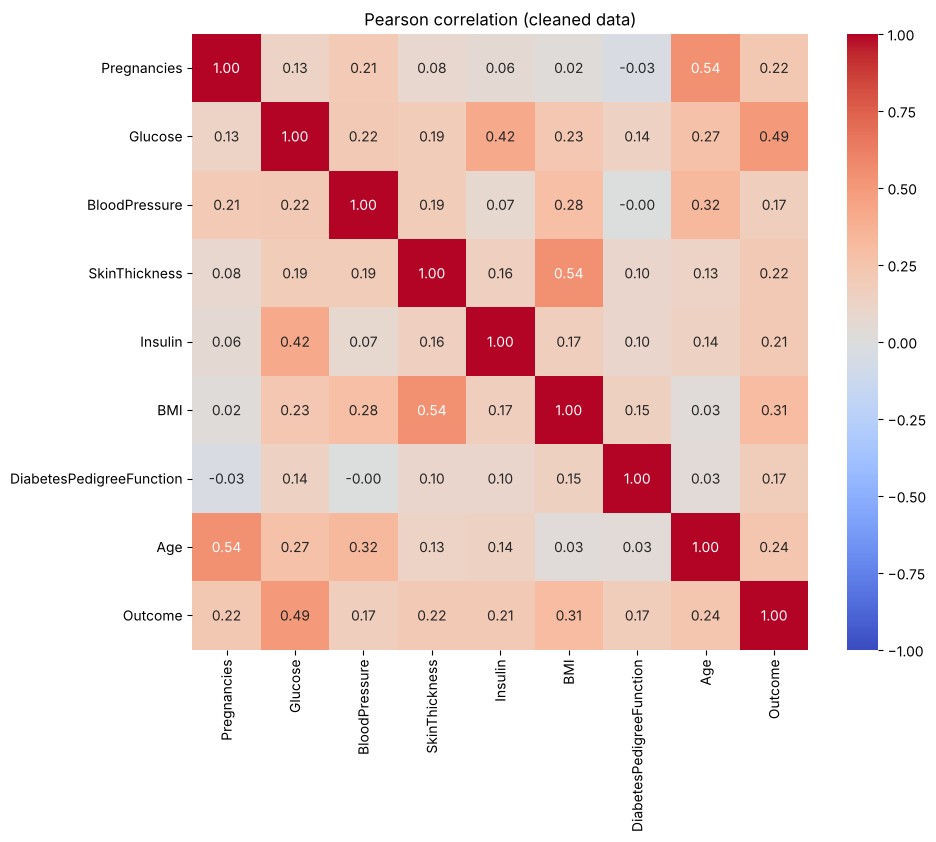

In [56]:
# Plot the correlation matrix. Please comment the results. Which features are more correlated?
corr_clean = data_clean[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_clean, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Pearson correlation (cleaned data)')
plt.show()

In [57]:
# Can you compare the previous results with the ones you get using data.corr()
corr_raw = data[numeric_cols].corr()
comparison = pd.DataFrame({'raw data (with zeros)': corr_raw['Outcome'],
                           'cleaned data': corr_clean['Outcome']}).round(3)
print("Correlation of each variable with Outcome:")
print(comparison)
print("\nLargest changes in the full matrix (cleaned - raw):")
diff = (corr_clean - corr_raw).round(3)
pairs = diff.where(np.triu(np.ones(diff.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
pairs.head(6)

Correlation of each variable with Outcome:
                          raw data (with zeros)  cleaned data
Pregnancies                               0.222         0.222
Glucose                                   0.467         0.493
BloodPressure                             0.065         0.166
SkinThickness                             0.075         0.215
Insulin                                   0.131         0.214
BMI                                       0.293         0.312
DiabetesPedigreeFunction                  0.174         0.174
Age                                       0.238         0.238
Outcome                                   1.000         1.000

Largest changes in the full matrix (cleaned - raw):


SkinThickness  Insulin         -0.279
               Age              0.242
Insulin        Age              0.179
Pregnancies    SkinThickness    0.165
SkinThickness  BMI              0.150
               Outcome          0.141
dtype: float64

**Comments.** The heatmap shows the Pearson correlation coefficient (from −1 to 1) between each pair of variables; `data.corr()` returns exactly the same numbers as a table (the heatmap is just a coloured version of it).
* The variable most correlated with **Outcome** is **Glucose** (r ≈ 0.49), followed by **BMI** (0.31), Age (0.24), Pregnancies (0.22) and SkinThickness/Insulin (0.21). These are the features expected to be most useful for classification.
* Between features, the strongest correlations are **Age – Pregnancies (0.54)** (older women have had more pregnancies), **SkinThickness – BMI (0.54 after cleaning)** (both measure body fat) and **Glucose – Insulin (0.42)**, which are physiologically coherent. No pair is extremely correlated (|r| > 0.8), so there is no severe multicollinearity.
* Comparing with the raw data: the zeros created **artificial correlations** (in the raw data SkinThickness–Insulin was 0.44 just because both are often 0 for the same patients; after cleaning it drops to 0.16), and hid real ones (Glucose–Insulin and SkinThickness–BMI increase after cleaning). Correlation of Outcome with BMI/Glucose also increases. Correlation only measures *linear* relationships.

##  12.-  Training, validation and test sets

In this section, the available cases will be separated into two subsets: a training subset and a test subset. The subsets will not share any case in common. The training subset will be used in the next modules to perform the learning of some models, and the test subset to evaluate their performance.

Before performing the separation into subsets, respond in a reasoned manner (justifying your response) to the following issues:

a) What percentage of available cases will you consider in the training subset? And in the test subset?

**Answer.** **70 % training (537 patients) and 30 % test (231 patients).** There is a trade-off: the model needs as many examples as possible to learn (especially the minority class, only 268 diabetics), but the test set must be large enough for its metrics to be reliable (with very few test cases one or two errors change the accuracy a lot). With 768 cases, 70/30 (or 80/20) is a reasonable compromise: ~80 diabetics remain in the test set. The **validation** set needed to tune hyper-parameters is not taken as a third fixed subset; instead we use **k-fold cross-validation inside the training set**, which uses the data more efficiently. The split should be **stratified** by Outcome so that both subsets keep the 65/35 proportion.

b) Consider that you build a binary classifier (two classes, C1 and C2). Discuss what would happen when evaluating the classifier's performance if the training subset with which the classifier is designed had almost all the cases of class C1 and the test subset had almost all the cases of class C2.

**Answer.** The classifier would learn almost exclusively what C1 looks like and would be biased to predict C1 (in the extreme it would predict C1 for everything, since it has barely seen C2). When evaluated on a test set made almost only of C2, it would misclassify most cases: very low accuracy and sensitivity for C2. Moreover, the evaluation would be meaningless: the test set would not represent the real population, so we could not estimate the true performance (we could not even compute a reliable specificity for C1). Training and test must come from the **same distribution**; this is guaranteed by a random (and preferably stratified) split.

c) How could you avoid overtraining in the design of the classifier? What would be the process to be followed to find the best parameters of that model?

**Answer.** Overtraining (overfitting) happens when the model memorises the training data, including noise, and fails on new data. To avoid it:
* Keep the test set completely untouched until the end and use **cross-validation** on the training set to choose the model.
* Control the **model complexity** (fewer parameters, lower polynomial degree, shallower trees), use **regularization** (Ridge/L2, Lasso/L1), **feature selection**, and/or get more data. Early stopping for iterative models.

Process to find the best parameters: (1) split train/test; (2) define a grid of candidate hyper-parameter values (e.g. regularization strength); (3) for each value, run k-fold cross-validation on the training set (train on k−1 folds, evaluate on the remaining one, repeat k times, average); (4) choose the value with the best mean validation score (ideally where training and validation curves are close); (5) retrain the model with that value on the whole training set; (6) evaluate it **once** on the test set. All preprocessing (scaling, imputation, resampling) must be fitted inside each training fold. `GridSearchCV` automates steps 2–5.

d) Explain which tools, from those presented in the course, you would use to roughly check whether each variable in the test subset follows the same distribution as the corresponding variable in the training subset.

**Answer.**
* **Descriptive statistics** (`describe()`): compare mean, std, median and quartiles of each variable in both subsets.
* **Overlaid histograms / density plots** and **side-by-side boxplots** of each variable, training vs test.
* **Class proportions** (`value_counts(normalize=True)`) for the target.
* For a more formal check (beyond a rough one): statistical tests like Kolmogorov–Smirnov (continuous variables) or χ² (categorical).

This is done in the code below.

e) Discuss what you should do with the original data set if you find that the distribution of the test subset cases is different from the distribution of the training subset.

**Answer.** It would mean the split is not representative (bad luck with a random split, or some ordering in the data). We should go back to the **original dataset** and repeat the split: shuffle the data and use a **stratified** split (by the class and, if needed, by key variables), or try another random seed and check again. Even better, use **k-fold cross-validation / repeated splits** so that the result does not depend on one particular partition. If the difference is due to real changes in the population (e.g. data from different hospitals or time periods), the problem is a *dataset shift*, and we would need more representative data or to collect data covering both distributions. What we must **never** do is modify the test set to make results look better.

### Hang on!

In [58]:
# Create the input and the output. Which is the shape of the input and the output?
X = data_clean[features]
y = data_clean['Outcome']
X.shape, y.shape

((768, 8), (768,))

The input X has 768 patients × 8 features; the output y is a vector with the 768 class labels.

In [59]:
# Split the data set in two different subsets: training and test
# IMPORTANT! The random state is used to obtain always the same partition.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Class proportions train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class proportions test: ", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (537, 8) Test: (231, 8)
Class proportions train: {0: 0.652, 1: 0.348}
Class proportions test:  {0: 0.649, 1: 0.351}


In [60]:
# Check results when considering different random_state values
for rs in [0, 1, 42, 123]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=rs)
    print(f"random_state={rs:3d}: test positives = {yte.mean():.3f} | mean Glucose train/test = "
          f"{Xtr.Glucose.mean():.1f} / {Xte.Glucose.mean():.1f} | first train indices {list(Xtr.index[:3])}")

random_state=  0: test positives = 0.320 | mean Glucose train/test = 122.5 / 119.9 | first train indices [580, 418, 764]
random_state=  1: test positives = 0.368 | mean Glucose train/test = 121.7 / 121.7 | first train indices [88, 467, 550]
random_state= 42: test positives = 0.346 | mean Glucose train/test = 122.0 / 121.0 | first train indices [334, 139, 485]
random_state=123: test positives = 0.381 | mean Glucose train/test = 121.0 / 123.2 | first train indices [429, 524, 212]


Changing `random_state` changes which patients go to each subset (different indices) and therefore slightly changes the statistics of each subset and, later, the performance of the models. Without stratification the proportion of diabetics in the test set varies from split to split; with `stratify=y` it is always ≈34.9 %. Fixing `random_state` makes the experiment **reproducible**.

In [61]:
# Rough check of question d): do train and test follow the same distribution?
comp = pd.DataFrame({'mean train': X_train.mean(), 'mean test': X_test.mean(),
                     'std train': X_train.std(), 'std test': X_test.std(),
                     'KS p-value': [stats.ks_2samp(X_train[c], X_test[c]).pvalue for c in features]}).round(3)
comp

,mean train,mean test,std train,std test,KS p-value
Pregnancies,3.883,3.758,3.350,3.420,0.946
Glucose,121.590,121.911,29.950,31.603,0.939
BloodPressure,72.245,72.779,12.187,11.902,0.763
SkinThickness,28.931,29.670,8.260,9.916,0.808
Insulin,152.621,162.354,78.795,97.828,0.840
BMI,32.618,32.084,6.731,7.201,0.096
DiabetesPedigreeFunction,0.481,0.452,0.335,0.322,0.489
Age,33.551,32.519,11.795,11.673,0.360


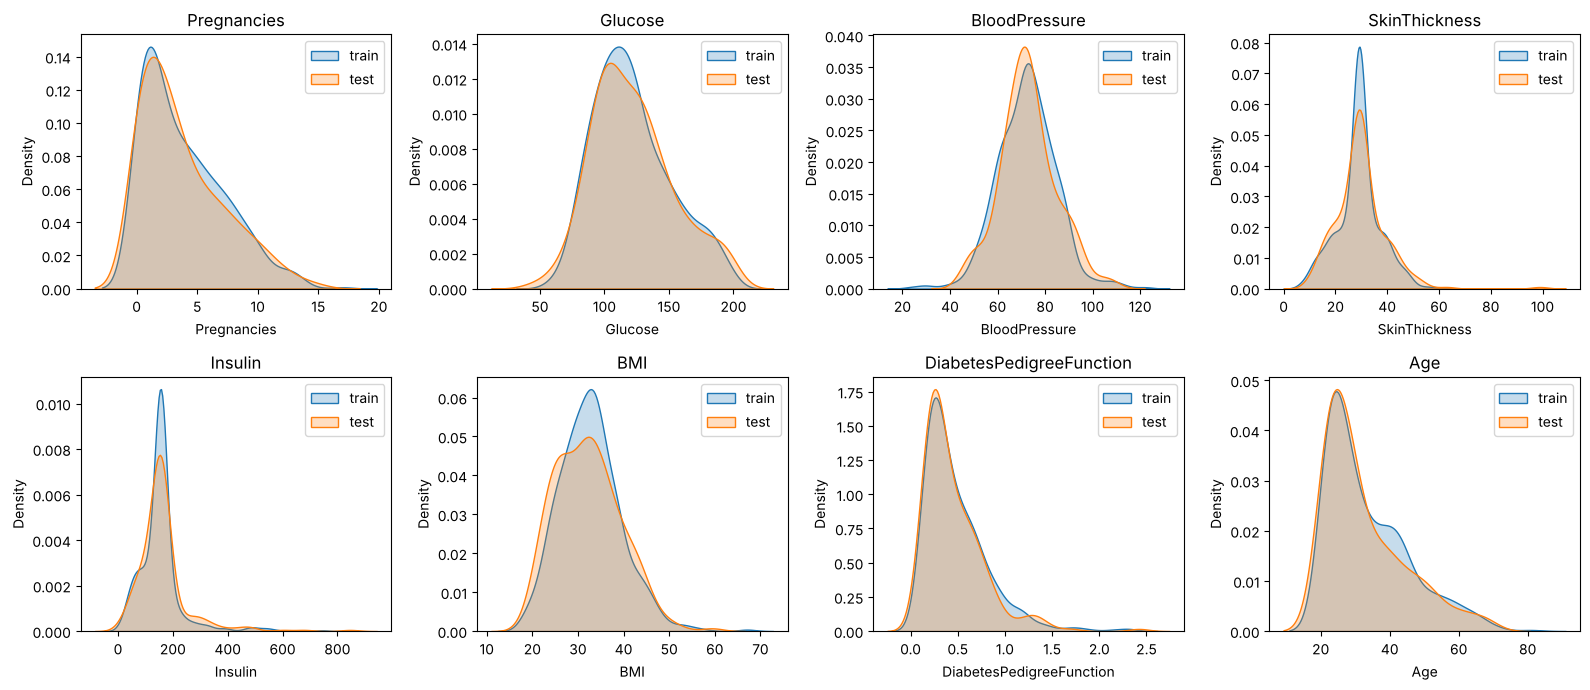

In [62]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(X_train[col], ax=ax, label='train', fill=True)
    sns.kdeplot(X_test[col], ax=ax, label='test', fill=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

Means, standard deviations and densities of train and test are very similar and all Kolmogorov–Smirnov p-values are > 0.05 (no evidence that the distributions differ), so the partition is representative.

In [63]:
# Normalize variables
# IMPORTANT!! You will use the mean and the standard deviation of the training set to normalize the test set
# In a real scenario, you don't know the test set in advance
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)  # fit ONLY on train
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=features, index=X_test.index)         # reuse train mean/std
print("Train means (≈0):", X_train_std.mean().round(3).values)
print("Test means (close to 0, but not exactly):", X_test_std.mean().round(3).values)
print("Test std (close to 1, but not exactly):  ", X_test_std.std().round(3).values)

Train means (≈0): [ 0.  0.  0.  0. -0.  0.  0. -0.]
Test means (close to 0, but not exactly): [-0.037  0.011  0.044  0.09   0.124 -0.079 -0.086 -0.088]
Test std (close to 1, but not exactly):   [1.022 1.056 0.978 1.202 1.243 1.071 0.961 0.991]


The scaler is **fitted only with the training data** (`fit_transform`) and the same μ and σ are applied to the test set (`transform`). That is why the training set has mean exactly 0 and std 1, while the test set has values only close to 0 and 1. If we fitted the scaler with the test data (or with all the data before splitting), information from the test set would leak into training (*data leakage*) and the evaluation would be optimistic.

### Save the preprocessed dataset (used in Labs 2 and 3)

In [64]:
# Preprocessed dataset: impossible zeros replaced by the mean of the valid values.
# - Outliers are kept (clinically plausible, see Section 7).
# - No resampling and no normalization here: they must be fitted on the training set only (inside each lab).
# - AgeCategory is not saved (it is redundant with Age).
preprocessed = data_clean.drop(columns='AgeCategory')
preprocessed.to_csv("pima_preprocessed.csv", index=False)
print(preprocessed.shape)
print("Remaining zeros:", (preprocessed[cols_missing] == 0).sum().sum(), "| NaN:", preprocessed.isnull().sum().sum())
preprocessed.head()

(768, 9)
Remaining zeros: 0 | NaN: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1
